Laboratorul 2 – Clasificare cu XGBoost

Scopul acestei părți a laboratorului este pregătirea datelor din Ames Housing și analizarea diferitelor strategii de preprocesare și validare pentru un model XGBoost care clasifică prețurile locuințelor în șase categorii.

Partea 0 – Pregătirea datelor

    Încărcarea dataset-ului și definirea celor șase clase de preț.
    Pregătirea caracteristicilor și a metodelor de encoding.
    Definirea funcțiilor comune pentru antrenarea și evaluarea modelului.

Partea A – Analiza și validarea modelului

    Analizarea distribuției claselor și a dezechilibrului dintre acestea.
    Compararea metodelor de encoding și a influenței feature engineering-ului.
    Analizarea efectului eliminării outlierilor.
    Compararea split-urilor de 10% și 20%, cu și fără stratificare.
    Compararea cross-validation cu 5 și 10 fold-uri.
    Analizarea learning curves, a overfitting-ului și a utilizării sample weights.
    
Pe baza rezultatelor se va stabili o configurație de bază pentru etapele următoare de optimizare.

In [2]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_RAW = ROOT / "data" / "raw"              # AmesHousing.csv (fisierul original, nu e in Git)
DATA_PROCESSED = ROOT / "data" / "processed"  # df.csv, df_fe.csv (generate de notebook-uri, nu sunt in Git)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "src"))         # ca sa functioneze `from common import ...`

In [4]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from common import make_classes, build_features, evaluate

df = pd.read_csv(ROOT / "df_fe.csv")

print("Dimensiunea dataset-ului:", df.shape)
display(df.head())


Dimensiunea dataset-ului: (2930, 96)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,YearsSinceRemod,Remodeled,TotalBath,TotalPorchSF,HasPool,HasFireplace,Has2ndFlr,HasBsmt,QualxLivArea,LivAreaPerRoom
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,50,0,2.0,272,0,1,0,1,9936,236.571429
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,49,0,1.0,260,0,0,0,1,4480,179.200000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,52,0,1.5,429,0,0,0,1,7974,221.500000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,42,0,3.5,0,0,1,0,1,14770,263.750000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,12,1,2.5,246,0,1,1,1,8145,271.500000


-Încărcarea și verificarea dataset-ului

În această etapă sunt importate bibliotecile necesare și funcțiile definite în `common.py`, utilizate pentru pregătirea datelor și evaluarea modelului XGBoost.

Este încărcat fișierul `df_fe.csv`, care conține dataset-ul Ames Housing după etapa de feature engineering din laboratorul anterior.

Dataset-ul conține 2930 de înregistrări și 96 de coloane, incluzând atât caracteristici numerice și categorice, cât și caracteristici noi, precum `TotalBath`, `TotalPorchSF` și `YearsSinceRemod`.

Sunt afișate primele cinci înregistrări pentru verificarea structurii datelor. În etapele următoare, acestea vor fi pregătite pentru clasificarea locuințelor în șase categorii de preț.

In [6]:

df["PriceClass"] = make_classes(df["SalePrice"])

test_prices = pd.Series([
    99999, 100000,
    129999, 130000,
    179999, 180000,
    249999, 250000,
    399999, 400000
])

expected_classes = [0, 1, 1, 2, 2, 3, 3, 4, 4, 5]
actual_classes = make_classes(test_prices)

assert actual_classes.tolist() == expected_classes
assert set(df["PriceClass"].unique()) == set(range(6))
assert df["PriceClass"].notna().all()

print("Distributia claselor:")
print(df["PriceClass"].value_counts().sort_index())

display(pd.DataFrame({
    "SalePrice": test_prices,
    "PriceClass": actual_classes
}))

print("verificarea make_classes a trecut")


Distributia claselor:
PriceClass
0     237
1     509
2    1037
3     686
4     397
5      64
Name: count, dtype: int64


,SalePrice,PriceClass
0,99999,0
1,100000,1
2,129999,1
3,130000,2
4,179999,2
5,180000,3
6,249999,3
7,250000,4
8,399999,4
9,400000,5


verificarea make_classes a trecut


-Definirea și verificarea claselor de preț

Variabila `SalePrice` este transformată în șase clase de preț, folosind funcția `make_classes()` din `common.py`, conform intervalelor stabilite în cerința laboratorului.

Pentru verificarea funcției sunt testate valorile de la limitele intervalelor, astfel încât fiecare preț să fie încadrat în clasa corespunzătoare. Testele confirmă că toate cele șase clase sunt prezente, nu există valori lipsă în `PriceClass`, iar clasificarea valorilor de la limite este corectă.

Distribuția rezultată arată un dezechilibru între clase. Clasa 2 conține cele mai multe locuințe (1037), în timp ce clasa 5 are doar 64 de înregistrări. Această diferență trebuie luată în considerare la antrenarea și evaluarea modelului, deoarece clasele mai puțin reprezentate pot fi mai dificil de identificat corect.

In [7]:
from common import build_features

X, y, preprocessor = build_features(df, encoding="onehot")

forbidden_cols = {
    "SalePrice",
    "SalePrice_log",
    "PriceClass",
    "Order",
    "PID"
}

assert len(X) == len(y) == len(df)
assert X.columns.is_unique
assert not X.isna().any().any()
assert not forbidden_cols.intersection(X.columns)
assert set(y.unique()) == set(range(6))
assert np.array_equal(y.to_numpy(), df["PriceClass"].to_numpy())

numeric_X = X.select_dtypes(include="number")
assert np.isfinite(numeric_X.to_numpy(dtype=float)).all()

for col in ["MS SubClass", "Mo Sold"]:
    if col in X.columns:
        assert pd.api.types.is_string_dtype(X[col])

print("Dimensiunea X:", X.shape)
print("Dimensiunea y:", y.shape)
print("Valori lipsa:", X.isna().sum().sum())
print("Coloane duplicate:", X.columns.duplicated().sum())
print("Coloane interzise:", forbidden_cols.intersection(X.columns))

print("\nverificarea build_features a trecut")



Dimensiunea X: (2930, 92)
Dimensiunea y: (2930,)
Valori lipsa: 0
Coloane duplicate: 0
Coloane interzise: set()

verificarea build_features a trecut


-Pregătirea și verificarea caracteristicilor

Funcția `build_features()` din `common.py` este utilizată pentru separarea caracteristicilor (`X`) de clasele de preț (`y`) și pregătirea preprocesorului cu metoda One-Hot Encoding.

Sunt efectuate mai multe verificări pentru a evita problemele legate de calitatea datelor și de *data leakage*. Coloanele asociate direct prețului, precum `SalePrice`, `SalePrice_log` și `PriceClass`, precum și identificatorii `Order` și `PID`, sunt excluse din caracteristicile modelului. De asemenea, se verifică existența valorilor lipsă, a coloanelor duplicate și a valorilor numerice infinite.

În urma pregătirii, X conține 2930 de înregistrări și 92 de caracteristici, iar `y` conține cele 2930 de clase corespunzătoare. Nu există valori lipsă, coloane duplicate sau coloane interzise, iar toate verificările au trecut.

Datele sunt astfel pregătite pentru etapele următoare de preprocesare și antrenare a modelului.

In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

validation_preprocessor = clone(preprocessor)

X_train_encoded = validation_preprocessor.fit_transform(X_train)
X_test_encoded = validation_preprocessor.transform(X_test)

assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert X_train_encoded.shape[0] == len(X_train)
assert X_test_encoded.shape[0] == len(X_test)
assert X_train_encoded.shape[1] == X_test_encoded.shape[1]
assert np.isfinite(X_train_encoded).all()
assert np.isfinite(X_test_encoded).all()
assert set(y_train.unique()) == set(range(6))
assert set(y_test.unique()) == set(range(6))

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistributia claselor in train:")
print(y_train.value_counts().sort_index())

print("\nDistributia claselor in test:")
print(y_test.value_counts().sort_index())

print("\nTrain encoded:", X_train_encoded.shape)
print("Test encoded:", X_test_encoded.shape)

print("\nverificarea split-ului si encoding-ului a trecut")


Train: (2344, 92)
Test: (586, 92)

Distributia claselor in train:
SalePrice
0    189
1    407
2    830
3    549
4    318
5     51
Name: count, dtype: int64

Distributia claselor in test:
SalePrice
0     48
1    102
2    207
3    137
4     79
5     13
Name: count, dtype: int64

Train encoded: (2344, 299)
Test encoded: (586, 299)

verificarea split-ului si encoding-ului a trecut


-Împărțirea datelor și aplicarea One-Hot Encoding

Dataset-ul este împărțit în 80% date de antrenare și 20% date de testare, folosind stratificarea pentru a păstra proporțiile celor șase clase de preț. Parametrul `random_state=42` permite reproducerea aceleiași împărțiri.

Preprocesorul este aplicat mai întâi pe datele de antrenare prin `fit_transform()`, iar datele de testare sunt transformate separat prin `transform()`. Astfel, informațiile din setul de test nu sunt folosite pentru învățarea transformărilor.

În urma împărțirii rezultă 2344 de înregistrări pentru antrenare și 586 pentru testare. După aplicarea One-Hot Encoding, numărul caracteristicilor crește de la 92 la 299, deoarece variabilele categorice sunt transformate în coloane numerice.

Verificările confirmă că seturile nu au înregistrări comune, conțin toate cele șase clase și au același număr de caracteristici după encoding. Distribuția claselor rămâne proporțională în ambele seturi, iar toate verificările au trecut.

In [9]:

model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

assert np.array_equal(model.classes_, np.arange(6))

print("modelul XGBoost a fost antrenat cu succes")


modelul XGBoost a fost antrenat cu succes


-Construirea și antrenarea modelului XGBoost

În această etapă este construit un model XGBoost pentru clasificarea locuințelor în cele șase categorii de preț. Se utilizează un `Pipeline` care combină preprocesarea datelor cu clasificatorul `XGBClassifier`, astfel încât transformările să fie aplicate automat înainte de antrenare.

Modelul folosește o configurație inițială de 100 de arbori, cu adâncimea maximă de 4 și rata de învățare de 0.1. Aceste valori reprezintă punctul de plecare pentru experimentele următoare, înainte de optimizarea hiperparametrilor.

Antrenarea se realizează pe setul `X_train`, folosind clasele corespunzătoare din `y_train`. Verificarea finală confirmă că modelul recunoaște toate cele șase clase, iar execuția s-a încheiat fără erori.

Modelul antrenat va fi utilizat în continuare pentru evaluarea performanței și compararea diferitelor configurații.

Rezultatele modelului:
accuracy: 0.7577
precision_macro: 0.7387
recall_macro: 0.7247
f1_macro: 0.7303
f1_weighted: 0.7570
roc_auc_macro_ovr: 0.9593
average_precision_macro: 0.8230
ROC-AUC per clasa: {0: 0.978, 1: 0.9339, 2: 0.9158, 3: 0.9517, 4: 0.9826, 5: 0.9937}
Average Precision per clasa: {0: 0.8297, 1: 0.7259, 2: 0.8445, 3: 0.8631, 4: 0.9049, 5: 0.7699}
Matricea de confuzie:
 [[ 33  13   2   0   0   0]
 [  7  72  23   0   0   0]
 [  1  19 170  15   1   1]
 [  0   0  25  97  14   1]
 [  0   0   1  11  64   3]
 [  0   0   0   0   5   8]]

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74        48
           1       0.69      0.71      0.70       102
           2       0.77      0.82      0.79       207
           3       0.79      0.71      0.75       137
           4       0.76      0.81      0.79        79
           5       0.62      0.62      0.62        13

    accuracy                           0.76      

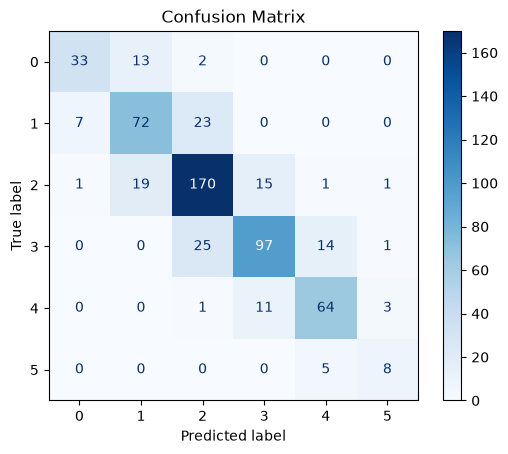

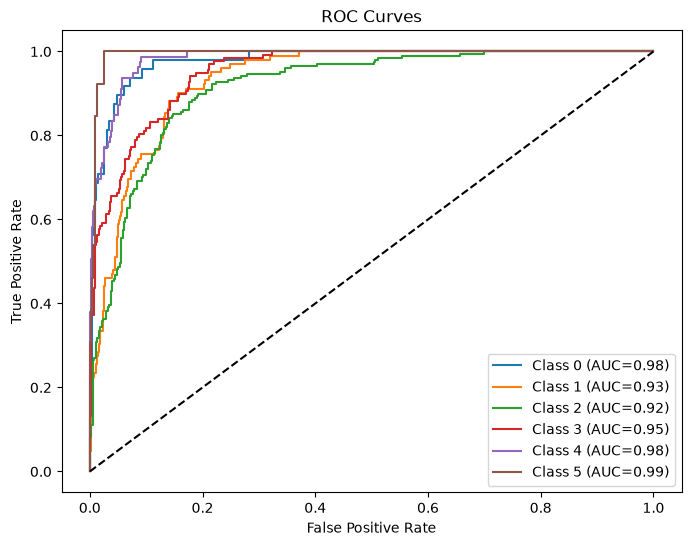

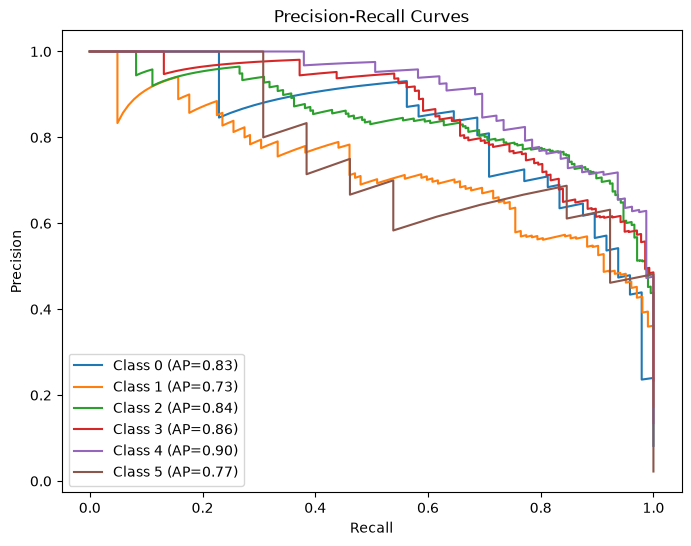


toate verificarile evaluarii au trecut


In [11]:

results = evaluate(
    model,
    X_test,
    y_test,
    show_plots=True
)

expected_metrics = {
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted"
}

assert expected_metrics.issubset(results)

for metric in expected_metrics:
    assert np.isfinite(results[metric])
    assert 0 <= results[metric] <= 1

print("\ntoate verificarile evaluarii au trecut")


-Evaluarea modelului XGBoost

Modelul XGBoost este evaluat pe setul de testare, folosind funcția `evaluate()` din `common.py`. Sunt calculate metricile Accuracy, Precision, Recall, Macro F1 și Weighted F1, împreună cu matricea de confuzie și curbele ROC și Precision-Recall.

Modelul obține o acuratețe de 0.7577 și un Macro F1 de 0.7303. Diferența dintre Macro F1 și Weighted F1 (0.7570) indică faptul că performanța nu este uniformă între clase, rezultatele fiind influențate și de numărul diferit de exemple din fiecare categorie.

Matricea de confuzie arată că majoritatea predicțiilor corecte se află pe diagonala principală. Cele mai multe confuzii apar între clasele vecine, de exemplu între clasele 1 și 2 sau între clasele 2 și 3. Acest lucru este explicabil prin apropierea intervalelor de preț.

Curbele ROC indică o capacitate bună de separare a claselor, cu un ROC-AUC macro de 0.9593. Curbele Precision-Recall arată însă diferențe între clase, valoarea Average Precision fiind mai redusă pentru clasa 1 (0.7259) și clasa 5 (0.7699).

Rezultatele reprezintă performanța configurației inițiale a modelului și vor servi drept punct de comparație pentru experimentele următoare.

In [13]:
def expect_error(func, *args, error_type=ValueError, **kwargs):
    try:
        func(*args, **kwargs)
    except error_type:
        return

    raise AssertionError(
        f"{func.__name__} nu a respins datele invalide."
    )

invalid_prices = [
    pd.Series([-100]),
    pd.Series([np.nan]),
    pd.Series([np.inf]),
    pd.Series(["invalid"])
]

for prices in invalid_prices:
    expect_error(make_classes, prices)

expect_error(
    build_features,
    df.drop(columns=["SalePrice"])
)

expect_error(
    build_features,
    df,
    encoding="invalid"
)


-Verificarea tratării datelor invalide

În această etapă este verificat modul în care funcțiile `make_classes()` și `build_features()` gestionează datele invalide. Pentru aceasta, este definită funcția auxiliară `expect_error()`, care verifică dacă o funcție respinge datele incorecte printr-o excepție de tip `ValueError`.

Pentru `make_classes()` sunt testate prețuri negative, valori lipsă (`NaN`), valori infinite și valori nenumerice. În cazul funcției `build_features()` sunt verificate două situații: lipsa coloanei obligatorii `SalePrice` și utilizarea unei metode de encoding neacceptate.

Scopul acestor teste este identificarea problemelor înainte de preprocesarea și antrenarea modelului. Dacă toate verificările trec, se confirmă că funcțiile resping cazurile invalide testate, în loc să continue prelucrarea unor date incorecte.

In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import make_classes, build_features, evaluate

df = pd.read_csv(ROOT / "df_fe.csv")

df["PriceClass"] = make_classes(df["SalePrice"])

print("Dimensiunea dataset-ului:", df.shape)
display(df[["SalePrice", "PriceClass"]].head())


Dimensiunea dataset-ului: (2930, 97)


,SalePrice,PriceClass
0,215000,3
1,105000,1
2,172000,2
3,244000,3
4,189900,3


-- A.1. Încărcarea datelor și pregătirea claselor

Pentru experimentele din Partea A este încărcat dataset-ul `df_fe.csv`, care conține datele Ames Housing după etapa de feature engineering.

Cu ajutorul funcției `make_classes()`, prețurile locuințelor din `SalePrice` sunt împărțite în cele șase categorii definite în cerința laboratorului. Clasele obținute sunt salvate în coloana `PriceClass`.

După adăugarea acestei coloane, dataset-ul conține 2930 de înregistrări și 97 de coloane, față de cele 96 inițiale. Primele cinci înregistrări confirmă corespondența dintre prețurile locuințelor și clasele atribuite.

Aceste date vor fi utilizate în continuare pentru analiza distribuției claselor și compararea strategiilor de pregătire și validare a modelului.

In [14]:

class_counts = (
    df["PriceClass"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    df["PriceClass"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

display(class_distribution)

print("Clasa majoritara:", class_counts.idxmax())
print("Clasa minoritara:", class_counts.idxmin())
print("Raport dezechilibru:", round(class_counts.max() / class_counts.min(), 2))


,Count,Percentage (%)
PriceClass,,
0,237,8.09
1,509,17.37
2,1037,35.39
3,686,23.41
4,397,13.55
5,64,2.18


Clasa majoritara: 2
Clasa minoritara: 5
Raport dezechilibru: 16.2


-- A.1. Analiza distribuției claselor

Pentru a verifica distribuția claselor de preț, sunt calculate numărul de înregistrări și procentul corespunzător fiecărei clase. Sunt identificate și clasele majoritară și minoritară, împreună cu raportul dintre acestea.

Rezultatele arată un dezechilibru semnificativ între clase. Clasa 2 este cea mai frecventă, cu 1037 de locuințe (35.39%), în timp ce clasa 5 conține doar 64 de locuințe (2.18%). Raportul de dezechilibru este de 16.2, ceea ce înseamnă că există de aproximativ 16 ori mai multe exemple în clasa majoritară decât în cea minoritară.

Acest dezechilibru poate influența antrenarea și evaluarea modelului, deoarece clasele cu mai puține exemple pot fi mai greu de identificat. Din acest motiv, în experimentele următoare vor fi analizate stratificarea și metodele de tratare a dezechilibrului, iar Macro F1 va fi utilizat pentru compararea performanței între clase.

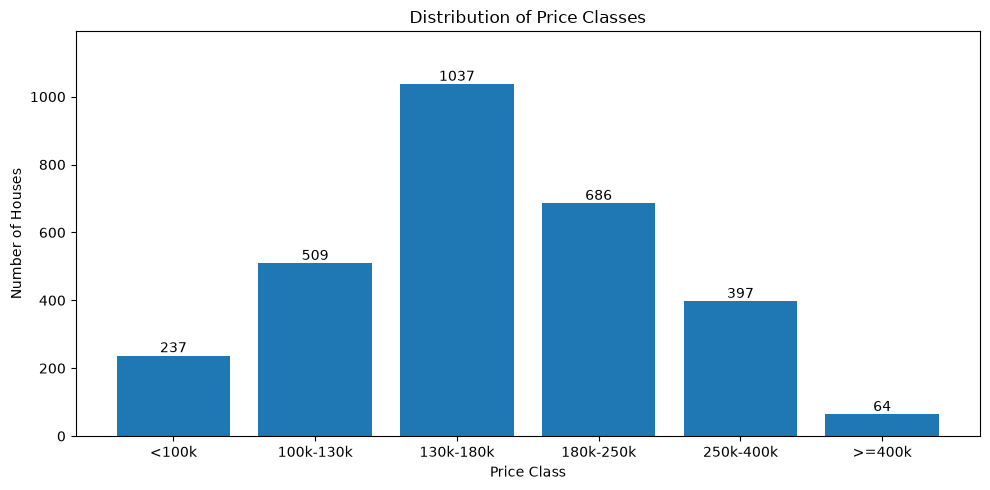

In [17]:

price_labels = [
    "<100k",
    "100k-130k",
    "130k-180k",
    "180k-250k",
    "250k-400k",
    ">=400k"
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    price_labels,
    class_counts.values
)

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        str(count),
        ha="center"
    )

plt.xlabel("Price Class")
plt.ylabel("Number of Houses")
plt.title("Distribution of Price Classes")
plt.ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()


--A.1. Vizualizarea distribuției claselor de preț

Distribuția celor șase clase de preț este reprezentată printr-un grafic cu bare, pentru a evidenția diferențele dintre numărul de locuințe din fiecare interval.

Graficul arată că cele mai multe locuințe se află în intervalul 130.000–180.000, corespunzător clasei 2, cu 1037 de înregistrări. Urmează clasa 3, cu 686 de locuințe, în timp ce clasa 5, care include prețurile de cel puțin 400.000, conține doar 64 de exemple.

Se observă că majoritatea locuințelor sunt concentrate în intervalele de preț medii, iar categoriile de la extremități sunt mai puțin reprezentate, în special cea cu prețurile cele mai ridicate.

Graficul confirmă dezechilibrul identificat anterior și evidențiază necesitatea evaluării performanței modelului pentru fiecare clasă, nu doar prin acuratețea generală.

In [18]:
import time

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

from common import build_features

X_onehot, y, preprocessor_onehot = build_features(
    df, encoding="onehot"
)

X_ordinal, _, preprocessor_ordinal = build_features(
    df, encoding="ordinal"
)

assert X_onehot.equals(X_ordinal)

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", len(train_idx))
print("Test:", len(test_idx))


Train: 2344
Test: 586


In [19]:

X_native = X_onehot.copy()

nominal_cols = X_native.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in nominal_cols:
    X_native[col] = X_native[col].astype("category")

assert len(X_native) == len(X_onehot)
assert not X_native.isna().any().any()

print("Coloane categorice native:", len(nominal_cols))
print("Dimensiunea X_native:", X_native.shape)


Coloane categorice native: 43
Dimensiunea X_native: (2930, 92)


--A.2. Compararea metodelor de encoding – Pregătirea datelor

Pentru compararea metodelor de encoding sunt pregătite trei variante: One-Hot Encoding, Ordinal Encoding și Native Categorical Encoding.

Primele două variante sunt definite folosind funcția `build_features()` din `common.py`. Pentru Native Encoding, coloanele categorice sunt convertite în tipul `category`, astfel încât XGBoost să le poată prelucra direct, fără transformarea lor în coloane binare.

Pentru o comparație în aceleași condiții, este stabilită o împărțire stratificată de 80% pentru antrenare și 20% pentru testare, rezultând 2344 și, respectiv, 586 de înregistrări.

În cazul variantei native sunt identificate 43 de coloane categorice, iar dataset-ul păstrează dimensiunea de 2930 de înregistrări și 92 de caracteristici.

Aceste pregătiri permit compararea ulterioară a performanței celor trei metode folosind aceleași date și aceeași configurație de bază a modelului.

In [20]:

X_train = X_onehot.iloc[train_idx]
X_test = X_onehot.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

strategies = {
    "One-hot": Pipeline([
        ("preprocessor", clone(preprocessor_onehot)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Ordinal": Pipeline([
        ("preprocessor", clone(preprocessor_ordinal)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Native": XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        enable_categorical=True,
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model_a2 in strategies.items():
    if name == "Native":
        X_train_current = X_native.iloc[train_idx]
        X_test_current = X_native.iloc[test_idx]
    else:
        X_train_current = X_train
        X_test_current = X_test

    start_time = time.perf_counter()

    model_a2.fit(X_train_current, y_train)

    training_time = time.perf_counter() - start_time

    predictions = model_a2.predict(X_test_current)

    comparison_results.append({
        "Strategy": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Macro F1",
        ascending=False
    ).round(4)
)


,Strategy,Accuracy,Macro F1,Weighted F1,Training Time (s)
2,Native,0.7713,0.7446,0.7711,1.0102
0,One-hot,0.7577,0.7303,0.7570,1.5353
1,Ordinal,0.7526,0.7233,0.7518,1.0223


-- A.2. Rezultatele comparării metodelor de encoding

Pentru compararea celor trei metode de encoding sunt antrenate modele XGBoost cu aceeași configurație de hiperparametri și aceeași împărțire a datelor. Sunt calculate Accuracy, Macro F1, Weighted F1 și timpul de antrenare.

Dintre cele trei variante, Native Encoding obține cele mai bune rezultate, cu Accuracy de 0.7713 și Macro F1 de 0.7446. Urmează One-Hot Encoding, cu Macro F1 de 0.7303, iar Ordinal Encoding obține 0.7233.

În ceea ce privește timpul de antrenare, varianta Ordinal este cea mai rapidă (1.0223 s), urmată de Native (1.1012 s). One-Hot necesită cel mai mult timp (1.5353 s), deoarece transformarea variabilelor categorice mărește numărul caracteristicilor.

Rezultatele indică un avantaj al metodei Native pentru această configurație și această împărțire a datelor. Totuși, diferențele de performanță sunt relativ mici, iar comparația este realizată pe un singur split.

Pentru experimentele următoare este păstrată varianta One-Hot ca metodă de referință, astfel încât rezultatele să fie comparabile și preprocesarea să poată fi integrată în același pipeline de evaluare.

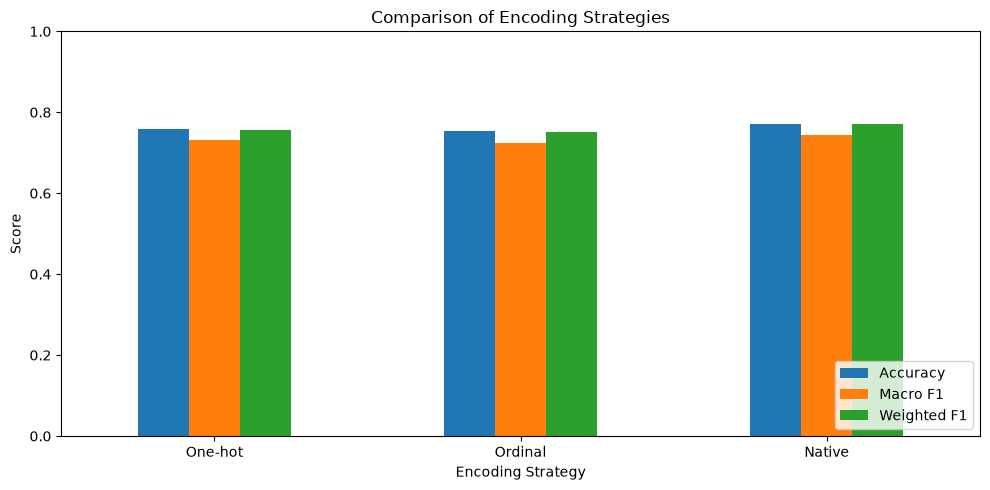

In [21]:

comparison_plot = comparison_df.set_index("Strategy")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Comparison of Encoding Strategies")
ax.set_ylabel("Score")
ax.set_xlabel("Encoding Strategy")
ax.set_ylim(0, 1)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


--A.2. Vizualizarea rezultatelor metodelor de encoding

Rezultatele celor trei metode de encoding sunt reprezentate printr-un grafic cu bare, folosind metricile Accuracy, Macro F1 și Weighted F1.

Graficul arată că Native Encoding obține cele mai bune valori pentru toate cele trei metrici, cu Accuracy de 0.7713 și Macro F1 de 0.7446. One-Hot Encoding are rezultate apropiate, cu Macro F1 de 0.7303, în timp ce Ordinal Encoding înregistrează cea mai redusă performanță, cu 0.7233.

Se observă și faptul că Macro F1 este mai mic decât Accuracy și Weighted F1 pentru toate metodele. Această diferență indică o performanță mai redusă pe unele clase, care devine mai vizibilă atunci când fiecare clasă are aceeași pondere în calculul scorului.

În această comparație, Native Encoding oferă cele mai bune rezultate, însă diferențele sunt relativ mici și au fost obținute pe o singură împărțire a datelor. Pentru experimentele următoare este păstrată varianta One-Hot ca metodă de referință, pentru a menține o configurație comună de preprocesare.

In [22]:

df_original = pd.read_csv("df.csv")
df_engineered = pd.read_csv("df_fe.csv")

new_features = sorted(
    set(df_engineered.columns) - set(df_original.columns)
)

print("Dataset original:", df_original.shape)
print("Dataset cu feature engineering:", df_engineered.shape)

print("\nFeature-uri noi:")
for feature in new_features:
    print("-", feature)

assert len(df_original) == len(df_engineered)
assert np.array_equal(
    df_original["SalePrice"].to_numpy(),
    df_engineered["SalePrice"].to_numpy()
)

print("\nVerificarea dataset-urilor a trecut.")


Dataset original: (2930, 83)
Dataset cu feature engineering: (2930, 96)

Feature-uri noi:
- Has2ndFlr
- HasBsmt
- HasFireplace
- HasPool
- HouseAge
- LivAreaPerRoom
- QualxLivArea
- Remodeled
- SalePrice_log
- TotalBath
- TotalPorchSF
- TotalSF
- YearsSinceRemod

Verificarea dataset-urilor a trecut.


--A.3. Compararea dataset-urilor cu și fără Feature Engineering

Pentru analizarea influenței feature engineering-ului sunt încărcate două versiuni ale dataset-ului Ames Housing: `df.csv`, care conține caracteristicile inițiale, și `df_fe.csv`, care include caracteristicile create în laboratorul anterior.

Dataset-ul original conține 2930 de înregistrări și 83 de coloane, iar cel cu feature engineering conține 2930 de înregistrări și 96 de coloane. Sunt identificate 13 coloane noi, printre care `HouseAge`, `TotalBath`, `TotalSF`, `TotalPorchSF` și `LivAreaPerRoom`.

Sunt verificate numărul de înregistrări și valorile din `SalePrice`, pentru a confirma că ambele versiuni conțin aceleași prețuri, în aceeași ordine.

Verificările au trecut, iar cele două dataset-uri pot fi utilizate în continuare pentru compararea performanței modelului cu și fără feature engineering.

In [23]:

common_columns = df_original.columns.intersection(
    df_engineered.columns
)

different_columns = []

for col in common_columns:
    if not df_original[col].equals(df_engineered[col]):
        different_columns.append(col)

print("Coloane comune:", len(common_columns))
print("Coloane cu valori diferite:", different_columns)

assert not different_columns, (
    f"Coloanele comune au valori diferite: {different_columns}"
)

print("Comparatia izoleaza feature-urile suplimentare.")


Coloane comune: 83
Coloane cu valori diferite: []
Comparatia izoleaza feature-urile suplimentare.


--A.3. Verificarea caracteristicilor comune

Pentru a realiza o comparație corectă între dataset-ul original și cel cu feature engineering, sunt verificate coloanele prezente în ambele versiuni.

Sunt identificate 83 de coloane comune, iar valorile acestora sunt comparate pentru a observa eventualele diferențe. Rezultatele arată că toate coloanele comune au valori identice, lista diferențelor fiind goală.

Această verificare confirmă că dataset-ul cu feature engineering păstrează datele originale și adaugă doar caracteristicile suplimentare identificate anterior. Astfel, comparația dintre cele două variante poate evidenția influența feature engineering-ului asupra performanței modelului.

In [ ]:
X_original, y_original, preprocessor_original = build_features(
    df_original,
    encoding="onehot"
)

X_engineered, y_engineered, preprocessor_engineered = build_features(
    df_engineered,
    encoding="onehot"
)

assert np.array_equal(
    y_original.to_numpy(),
    y_engineered.to_numpy()
)

train_idx, test_idx = train_test_split(
    np.arange(len(y_original)),
    test_size=0.2,
    stratify=y_original,
    random_state=42
)

X_train_original = X_original.iloc[train_idx]
X_test_original = X_original.iloc[test_idx]

X_train_engineered = X_engineered.iloc[train_idx]
X_test_engineered = X_engineered.iloc[test_idx]

y_train_a3 = y_original.iloc[train_idx]
y_test_a3 = y_original.iloc[test_idx]

print("Original X:", X_original.shape)
print("Engineered X:", X_engineered.shape)
print("Train:", len(train_idx))
print("Test:", len(test_idx))

Original X: (2930, 80)
Engineered X: (2930, 92)
Train: 2344
Test: 586


-- A.3. Pregătirea datelor pentru compararea Feature Engineering

Pentru compararea celor două variante sunt pregătite caracteristicile și clasele de preț folosind funcția `build_features()` și metoda One-Hot Encoding.

Dataset-ul original conține 80 de caracteristici, iar cel cu feature engineering conține 92. Diferența de 12 caracteristici provine din variabilele suplimentare create anterior, fără includerea coloanei `SalePrice_log`, care ar putea produce data leakage.

Se verifică dacă variabila țintă este identică în ambele dataset-uri, apoi se realizează o împărțire stratificată de 80% pentru antrenare și 20% pentru testare. Rezultă 2344 de înregistrări pentru antrenare și 586 pentru testare.

Aceiași indici sunt utilizați pentru ambele variante, astfel încât modelele să fie antrenate și evaluate pe aceleași locuințe. În acest mod, comparația urmărește influența caracteristicilor suplimentare asupra performanței clasificării.

In [25]:

feature_sets = {
    "Without FE": (
        X_train_original,
        X_test_original,
        preprocessor_original
    ),
    "With FE": (
        X_train_engineered,
        X_test_engineered,
        preprocessor_engineered
    )
}

fe_results = []

for name, (X_train_current, X_test_current, prep) in feature_sets.items():

    model_fe = Pipeline([
        ("preprocessor", clone(prep)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()

    model_fe.fit(X_train_current, y_train_a3)

    training_time = time.perf_counter() - start_time

    predictions = model_fe.predict(X_test_current)

    fe_results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_test_a3, predictions),
        "Macro F1": f1_score(
            y_test_a3,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_a3,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

fe_comparison_df = pd.DataFrame(fe_results)

display(fe_comparison_df.round(4))


,Feature Set,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,Without FE,0.7440,0.7155,0.742,1.4163
1,With FE,0.7577,0.7303,0.757,1.4959


--A.3. Rezultatele comparării cu și fără Feature Engineering

Pentru evaluarea influenței feature engineering-ului sunt antrenate două modele XGBoost, unul folosind caracteristicile originale și celălalt folosind caracteristicile suplimentare. Ambele variante utilizează One-Hot Encoding, aceiași hiperparametri și aceeași împărțire a datelor.

Modelul fără feature engineering obține Accuracy de 0.7440 și Macro F1 de 0.7155. După includerea caracteristicilor suplimentare, Accuracy crește la 0.7577, iar Macro F1 la 0.7303.

Diferența de Macro F1 este de 0.0148, ceea ce indică o îmbunătățire a performanței în experimentul realizat. Timpul de antrenare crește ușor, de la 1.4163 la 1.4959 secunde.

Rezultatele sugerează că noile caracteristici oferă informații utile modelului. Totuși, comparația este realizată pe o singură împărțire train-test, astfel încât îmbunătățirea observată nu garantează același rezultat pentru alte împărțiri sau configurații.

Pentru experimentele următoare este păstrat dataset-ul cu feature engineering, deoarece a obținut rezultate mai bune pentru toate cele trei metrici evaluate.

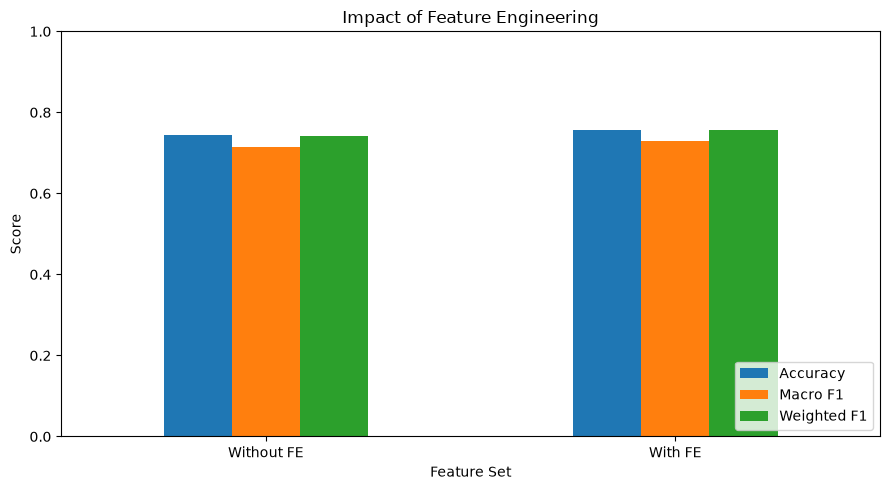

In [26]:

fe_plot = fe_comparison_df.set_index("Feature Set")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = fe_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Impact of Feature Engineering")
ax.set_xlabel("Feature Set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


-- A.3. Vizualizarea impactului Feature Engineering

Rezultatele modelelor antrenate cu și fără feature engineering sunt reprezentate printr-un grafic cu bare, folosind metricile Accuracy, Macro F1 și Weighted F1.

Se observă că varianta cu feature engineering obține valori mai mari pentru toate cele trei metrici. Accuracy crește de la 0.7440 la 0.7577, iar Macro F1 de la 0.7155 la 0.7303. Weighted F1 crește, de asemenea, de la 0.7420 la 0.7570.

Deși diferențele nu sunt foarte mari, rezultatele indică un avantaj al utilizării caracteristicilor suplimentare în configurația testată. Prin urmare, dataset-ul cu feature engineering va fi păstrat pentru experimentele următoare.

Graficul confirmă rezultatele numerice obținute anterior, însă îmbunătățirea observată este valabilă pentru împărțirea datelor și hiperparametrii utilizați în acest experiment.

In [27]:

without_fe = fe_comparison_df.loc[
    fe_comparison_df["Feature Set"] == "Without FE"
].iloc[0]

with_fe = fe_comparison_df.loc[
    fe_comparison_df["Feature Set"] == "With FE"
].iloc[0]

metrics = ["Accuracy", "Macro F1", "Weighted F1"]

print("Diferenta With FE - Without FE:")

for metric in metrics:
    difference = with_fe[metric] - without_fe[metric]
    print(f"{metric}: {difference:+.4f}")


Diferenta With FE - Without FE:
Accuracy: +0.0137
Macro F1: +0.0148
Weighted F1: +0.0150


-- A.3. Calcularea diferențelor de performanță

Pentru a evidenția mai clar influența feature engineering-ului, sunt calculate diferențele dintre scorurile obținute cu și fără caracteristicile suplimentare.

Rezultatele arată o creștere a Accuracy cu 0.0137, a Macro F1 cu 0.0148 și a Weighted F1 cu 0.0150. Toate diferențele sunt pozitive, ceea ce confirmă îmbunătățirea performanței pentru configurația testată.

Creșterea Macro F1 cu 1.48 puncte procentuale este relevantă pentru acest experiment, deoarece această metrică acordă aceeași importanță tuturor celor șase clase de preț.

Pe baza rezultatelor obținute, varianta cu feature engineering este păstrată pentru experimentele următoare. Totuși, îmbunătățirea observată este relativ mică și ar trebui verificată și pe alte împărțiri ale datelor pentru a stabili dacă se menține.

In [28]:

partial_houses = df_engineered.loc[
    df_engineered["Sale Condition"] == "Partial"
].copy()

print("Numar total de case Partial:", len(partial_houses))

display(
    partial_houses[
        ["SalePrice", "Gr Liv Area", "Sale Condition"]
    ].sort_values("Gr Liv Area", ascending=False).head(10)
)


Numar total de case Partial: 245


,SalePrice,Gr Liv Area,Sale Condition
1498,160000,5642,Partial
2180,183850,5095,Partial
2181,184750,4676,Partial
2330,545224,3390,Partial
422,485000,3140,Partial
2336,438780,2945,Partial
2332,556581,2868,Partial
2097,424870,2828,Partial
433,582933,2822,Partial
2329,457347,2798,Partial


-- A.4. Identificarea locuințelor cu vânzare parțială

Pentru analiza valorilor extreme sunt selectate locuințele care au `Sale Condition` egal cu `Partial`. Această categorie este analizată separat deoarece poate include tranzacții cu caracteristici diferite față de vânzările obișnuite.
În dataset sunt identificate 245 de locuințe din această categorie. Pentru o primă verificare, sunt afișate cele 10 înregistrări cu cele mai mari valori ale caracteristicii `Gr Liv Area`, împreună cu prețul de vânzare.
Rezultatele arată că unele locuințe au suprafețe locuibile foarte mari, dar prețuri care nu cresc proporțional cu acestea. De exemplu, o locuință cu `Gr Liv Area` de 5642 are un preț de vânzare de 160000, iar una cu suprafața de 5095 are un preț de 183850.
Aceste observații pot indica posibile valori extreme în relația dintre suprafața locuibilă și preț. În etapele următoare va fi analizat dacă eliminarea unor astfel de înregistrări influențează performanța modelului.

In [29]:

partial_candidates = df_engineered.loc[
    df_engineered["Sale Condition"].eq("Partial")
    & df_engineered["Gr Liv Area"].gt(3000),
    ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
].copy()

display(
    partial_candidates.sort_values(
        "Gr Liv Area",
        ascending=False
    )
)

print("Numar candidati:", len(partial_candidates))


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial
2330,527210040,545224,3390,Partial
422,528104070,485000,3140,Partial


Numar candidati: 5


--A.4. Identificarea candidaților pentru valori extreme
Pentru identificarea posibilelor valori extreme sunt selectate locuințele care au `Sale Condition` egal cu `Partial` și `Gr Liv Area` mai mare de 3000. Sunt afișate identificatorul `PID`, prețul de vânzare, suprafața locuibilă și condiția vânzării.
În urma filtrării sunt identificate 5 locuințe. Dintre acestea, trei au suprafețe locuibile foarte mari, între 4676 și 5642, dar prețuri de vânzare cuprinse între 160000 și 184750. Celelalte două locuințe au suprafețe de 3140 și 3390, însă prețurile lor sunt considerabil mai ridicate.
Diferențele observate sugerează că primele trei înregistrări ar putea reprezenta valori extreme în relația dintre suprafața locuibilă și preț. Acestea vor fi analizate în continuare pentru a verifica dacă eliminarea lor din datele de antrenare influențează performanța modelului.

In [30]:
import pandas as pd

df_engineered = pd.read_csv("df_fe.csv")
partial_candidates = df_engineered.loc[
    df_engineered["Sale Condition"] == "Partial",
    ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
].copy()

print("Numar case Partial:", len(partial_candidates))

display(
    partial_candidates.sort_values(
        "Gr Liv Area",
        ascending=False
    ).head(20)
)


Numar case Partial: 245


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial
2330,527210040,545224,3390,Partial
422,528104070,485000,3140,Partial
2336,527216050,438780,2945,Partial
2332,527212030,556581,2868,Partial
2097,906340090,424870,2828,Partial
433,528110090,582933,2822,Partial
2329,527210030,457347,2798,Partial


-A.4. Analiza locuințelor cu vânzare de tip Partial
Pentru o analiză mai detaliată a posibilelor valori extreme sunt selectate toate locuințele cu `Sale Condition` egal cu `Partial`. Acestea sunt ordonate descrescător după `Gr Liv Area`, fiind afișate primele 20 de înregistrări, împreună cu identificatorul `PID` și prețul de vânzare.
În total sunt identificate 245 de locuințe din această categorie. Primele trei înregistrări au suprafețe locuibile cuprinse între 4676 și 5642, dar prețuri de vânzare între 160000 și 184750. În comparație, alte locuințe cu suprafețe mai mici au prețuri considerabil mai ridicate.
Această observație susține selectarea primelor trei locuințe drept posibili outlieri în relația dintre suprafața locuibilă și preț. Totuși, identificarea lor nu înseamnă automat că datele sunt incorecte sau că trebuie eliminate. Impactul eliminării va fi verificat ulterior prin compararea performanței modelului.

In [31]:
outlier_pids = [
    908154235,
    908154195,
    908154205
]


assert len(outlier_pids) == 3, (
    "Introdu exact cele 3 PID-uri ale outlierilor din L1."
)

outlier_mask = df_engineered["PID"].isin(outlier_pids)

assert outlier_mask.sum() == 3, (
    "Nu au fost identificate exact 3 observatii."
)

print("Outlierii identificati:")
display(
    df_engineered.loc[
        outlier_mask,
        ["PID", "SalePrice", "Gr Liv Area", "Sale Condition"]
    ]
)

Outlierii identificati:


,PID,SalePrice,Gr Liv Area,Sale Condition
1498,908154235,160000,5642,Partial
2180,908154195,183850,5095,Partial
2181,908154205,184750,4676,Partial


--A.4. Selectarea și verificarea outlierilor
Pe baza analizei anterioare sunt selectate trei locuințe care prezintă suprafețe locuibile foarte mari în raport cu prețurile de vânzare. Acestea sunt identificate prin valorile `PID`: 908154235, 908154195 și 908154205.
Pentru a verifica selecția, este creată o mască folosind coloana `PID`, iar apoi se verifică dacă în dataset există exact trei înregistrări corespunzătoare. Rezultatul confirmă identificarea tuturor celor trei locuințe.
Suprafețele acestora sunt cuprinse între 4676 și 5642, iar prețurile între 160000 și 184750. Aceste observații sunt considerate posibili outlieri și vor fi utilizate în experimentul următor pentru a compara performanța modelului cu și fără eliminarea lor din datele de antrenare.
În această etapă, înregistrările sunt doar identificate și verificate, fără a fi eliminate din dataset.

In [32]:
from common import build_features
from sklearn.model_selection import train_test_split
import numpy as np
X_a4, y_a4, preprocessor_a4 = build_features(
    df_engineered,
    encoding="onehot"
)

train_idx_a4, test_idx_a4 = train_test_split(
    np.arange(len(y_a4)),
    test_size=0.2,
    stratify=y_a4,
    random_state=42
)

train_outlier_mask = outlier_mask.iloc[train_idx_a4].to_numpy()

X_train_full = X_a4.iloc[train_idx_a4]
y_train_full = y_a4.iloc[train_idx_a4]

X_train_clean = X_train_full.loc[
    ~train_outlier_mask
]

y_train_clean = y_train_full.loc[
    ~train_outlier_mask
]

X_test_a4 = X_a4.iloc[test_idx_a4]
y_test_a4 = y_a4.iloc[test_idx_a4]

print("Train cu outlieri:", X_train_full.shape)
print("Train fara outlieri:", X_train_clean.shape)
print("Test comun:", X_test_a4.shape)

print(
    "Outlieri eliminati din train:",
    train_outlier_mask.sum()
)


Train cu outlieri: (2344, 92)
Train fara outlieri: (2343, 92)
Test comun: (586, 92)
Outlieri eliminati din train: 1


-- A.4. Pregătirea datelor pentru evaluarea outlierilor
Pentru a analiza influența valorilor extreme asupra performanței modelului, dataset-ul cu feature engineering este împărțit în 80% date de antrenare și 20% date de testare, folosind o împărțire stratificată.
Sunt pregătite două variante ale setului de antrenare: una care păstrează toate înregistrările și una din care sunt eliminați outlierii identificați anterior. Setul de testare rămâne identic pentru ambele variante, astfel încât rezultatele să poată fi comparate în aceleași condiții.
În urma împărțirii, setul inițial de antrenare conține 2344 de înregistrări, iar cel fără outlieri conține 2343. Diferența de o singură înregistrare apare deoarece doar unul dintre cei trei outlieri identificați se află în setul de antrenare, ceilalți doi fiind în setul de testare.
Această abordare permite evaluarea efectului eliminării valorilor extreme din datele de antrenare, fără modificarea setului de testare.

In [33]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import time
import pandas as pd


outlier_results = []

training_sets = {
    "With Outliers": (X_train_full, y_train_full),
    "Without Outliers": (X_train_clean, y_train_clean)
}

for name, (X_train_current, y_train_current) in training_sets.items():

    model_a4 = Pipeline([
        ("preprocessor", clone(preprocessor_a4)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()

    model_a4.fit(X_train_current, y_train_current)

    training_time = time.perf_counter() - start_time

    predictions = model_a4.predict(X_test_a4)

    outlier_results.append({
        "Dataset": name,
        "Train Samples": len(X_train_current),
        "Accuracy": accuracy_score(y_test_a4, predictions),
        "Macro F1": f1_score(
            y_test_a4,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_a4,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

outlier_comparison_df = pd.DataFrame(outlier_results)

display(outlier_comparison_df.round(4))


,Dataset,Train Samples,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,With Outliers,2344,0.7577,0.7303,0.7570,1.6448
1,Without Outliers,2343,0.7543,0.7437,0.7534,1.5981


--A.4. Compararea performanței cu și fără outlieri
Pentru evaluarea influenței valorilor extreme sunt antrenate două modele XGBoost, folosind aceiași hiperparametri, aceeași metodă One-Hot Encoding și același set de testare. Prima variantă păstrează toate cele 2344 de înregistrări din train, iar a doua elimină singurul outlier identificat în acest set.
Modelul antrenat cu outlieri obține Accuracy de 0.7577 și Macro F1 de 0.7303. După eliminarea outlierului, Accuracy scade ușor la 0.7543, în timp ce Macro F1 crește la 0.7437. Weighted F1 scade de la 0.7570 la 0.7534.
Rezultatele arată că eliminarea outlierului a îmbunătățit Macro F1 cu 0.0134, dar nu și celelalte două metrici. Acest lucru sugerează un posibil avantaj pentru performanța medie pe cele șase clase, fără o îmbunătățire generală a clasificării.
Deoarece experimentul folosește o singură împărțire train-test și elimină doar o înregistrare, rezultatele nu sunt suficiente pentru a recomanda definitiv eliminarea outlierilor. Este necesară o evaluare suplimentară, de exemplu prin cross-validation, pentru a verifica stabilitatea diferențelor observate.

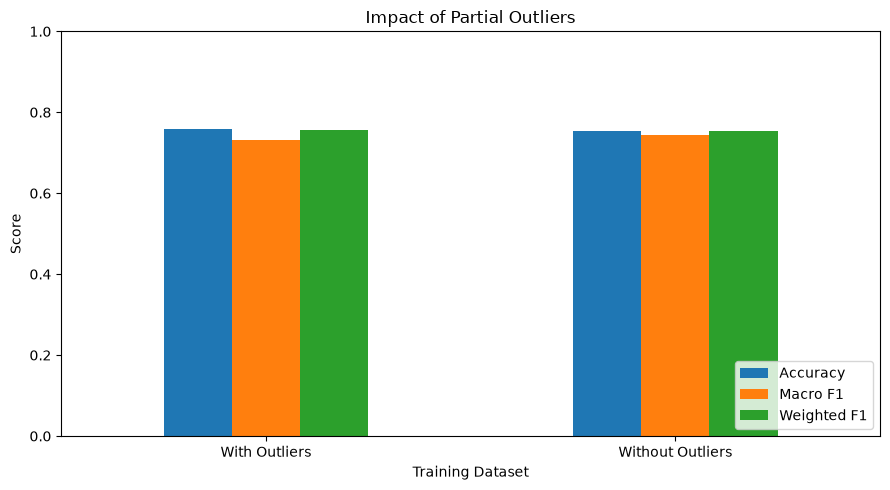

In [34]:

import matplotlib.pyplot as plt

outlier_plot = outlier_comparison_df.set_index("Dataset")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = outlier_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Impact of Partial Outliers")
ax.set_xlabel("Training Dataset")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()



--A.4. Vizualizarea impactului outlierilor
Pentru a compara mai ușor rezultatele celor două variante, sunt reprezentate grafic metricile Accuracy, Macro F1 și Weighted F1, folosind valorile obținute în experimentul anterior.
Se observă că eliminarea outlierului din setul de antrenare produce modificări relativ mici ale performanței. Accuracy scade de la 0.7577 la 0.7543, iar Weighted F1 de la 0.7570 la 0.7534. În schimb, Macro F1 crește de la 0.7303 la 0.7437.
Creșterea Macro F1 sugerează o îmbunătățire a performanței medii pe cele șase clase, însă celelalte două metrici nu confirmă un avantaj general al eliminării outlierului.
Deoarece comparația este realizată pe o singură împărțire train-test și este eliminată doar o înregistrare, rezultatele trebuie interpretate cu prudență. Pentru o decizie mai bine fundamentată este necesară compararea celor două variante prin cross-validation.

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

from common import build_features

df_a5 = pd.read_csv("df_fe.csv")

X_a5, y_a5, preprocessor_a5 = build_features(
    df_a5,
    encoding="onehot"
)

split_strategies = [
    ("10% Stratified", 0.10, True),
    ("10% Non-stratified", 0.10, False),
    ("20% Stratified", 0.20, True),
    ("20% Non-stratified", 0.20, False)
]

print("Dataset:", X_a5.shape)
print("Numar clase:", y_a5.nunique())
print("Strategii de comparat:", len(split_strategies))


Dataset: (2930, 92)
Numar clase: 6
Strategii de comparat: 4


-- A.5. Pregătirea strategiilor de împărțire train-test
Pentru a analiza influența împărțirii datelor asupra performanței modelului XGBoost, sunt definite patru strategii train-test, folosind procente de testare de 10% și 20%, atât cu stratificare, cât și fără stratificare.
Este utilizat dataset-ul cu feature engineering, iar caracteristicile sunt pregătite prin funcția `build_features()`, folosind One-Hot Encoding. Rezultă 2930 de înregistrări și 92 de caracteristici, iar variabila țintă conține șase clase de preț.
Strategiile stratificate păstrează aproximativ proporțiile claselor în seturile de antrenare și testare, în timp ce strategiile nestratificate realizează împărțirea fără această condiție.
Scopul experimentului este de a observa cum influențează dimensiunea setului de testare și stratificarea rezultatele clasificării, pentru a alege o strategie potrivită pentru experimentele următoare.

In [36]:

split_results = []
class_distributions = []

for name, test_size, stratified in split_strategies:

    X_train, X_test, y_train, y_test = train_test_split(
        X_a5,
        y_a5,
        test_size=test_size,
        random_state=42,
        stratify=y_a5 if stratified else None
    )

    model_a5 = Pipeline([
        ("preprocessor", clone(preprocessor_a5)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.perf_counter()
    model_a5.fit(X_train, y_train)
    training_time = time.perf_counter() - start_time

    predictions = model_a5.predict(X_test)

    split_results.append({
        "Strategy": name,
        "Train Samples": len(X_train),
        "Test Samples": len(X_test),
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions,
            labels=np.arange(6),
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions,
            labels=np.arange(6),
            average="weighted",
            zero_division=0
        ),
        "Training Time (s)": training_time
    })

    for class_id in range(6):
        class_distributions.append({
            "Strategy": name,
            "Class": class_id,
            "Train Count": int((y_train == class_id).sum()),
            "Test Count": int((y_test == class_id).sum()),
            "Test Percentage": 100 * (y_test == class_id).mean()
        })

split_comparison_df = pd.DataFrame(split_results)
class_distribution_df = pd.DataFrame(class_distributions)

display(split_comparison_df.round(4))


,Strategy,Train Samples,Test Samples,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,10% Stratified,2637,293,0.7338,0.7485,0.7353,1.5692
1,10% Non-stratified,2637,293,0.7406,0.7066,0.7381,1.5598
2,20% Stratified,2344,586,0.7577,0.7303,0.7570,1.5411
3,20% Non-stratified,2344,586,0.7679,0.7492,0.7662,1.5654


--A.5. Compararea strategiilor de împărțire train-test
Pentru a analiza influența împărțirii datelor asupra performanței modelului XGBoost, sunt testate patru strategii: 10% și 20% pentru testare, fiecare cu și fără stratificare. Toate variantele folosesc aceiași hiperparametri, One-Hot Encoding și `random_state=42`.
Pentru împărțirea de 10%, sunt utilizate 2637 de înregistrări pentru antrenare și 293 pentru testare. În cazul împărțirii de 20%, sunt utilizate 2344 de înregistrări pentru antrenare și 586 pentru testare.
Rezultatele arată că strategia `20% Non-stratified` obține cea mai mare Accuracy, de 0.7679, în timp ce `20% Stratified` obține cel mai mare Weighted F1, de 0.7570. Pentru Macro F1, cea mai mare valoare este obținută de `20% Non-stratified`, cu 0.7492, urmată foarte aproape de `10% Stratified`, cu 0.7485.
Strategia `10% Non-stratified` obține cel mai mic Macro F1, de 0.7066, ceea ce arată că împărțirea datelor poate influența rezultatele evaluării.
Deși varianta `20% Non-stratified` obține cel mai bun Macro F1 în această comparație, rezultatul provine dintr-o singură împărțire a datelor. Pentru experimentele următoare este preferată împărțirea stratificată 80/20, deoarece păstrează aproximativ proporțiile claselor și oferă un set de testare suficient de mare pentru evaluarea celor șase clase de preț.

In [38]:

test_distribution = class_distribution_df.pivot(
    index="Strategy",
    columns="Class",
    values="Test Count"
)

test_distribution = test_distribution.reindex(
    [strategy[0] for strategy in split_strategies]
)

print("Distributia claselor in seturile de test:")
display(test_distribution)

print("\nProportia claselor in test (%):")

test_percentages = class_distribution_df.pivot(
    index="Strategy",
    columns="Class",
    values="Test Percentage"
)

test_percentages = test_percentages.reindex(
    [strategy[0] for strategy in split_strategies]
)

display(test_percentages.round(2))


Distributia claselor in seturile de test:


Class,0,1,2,3,4,5
Strategy,,,,,,
10% Stratified,24,51,104,68,40,6
10% Non-stratified,25,47,85,79,47,10
20% Stratified,48,102,207,137,79,13
20% Non-stratified,51,92,191,138,94,20



Proportia claselor in test (%):


Class,0,1,2,3,4,5
Strategy,,,,,,
10% Stratified,8.19,17.41,35.49,23.21,13.65,2.05
10% Non-stratified,8.53,16.04,29.01,26.96,16.04,3.41
20% Stratified,8.19,17.41,35.32,23.38,13.48,2.22
20% Non-stratified,8.70,15.70,32.59,23.55,16.04,3.41


--A.5. Compararea distribuției claselor în seturile de testare
Pentru a analiza diferențele dintre strategiile de împărțire, sunt comparate numărul de înregistrări și proporția fiecărei clase de preț în seturile de testare.
Rezultatele arată că strategiile stratificate păstrează aproximativ aceleași proporții ale claselor, indiferent dacă pentru testare sunt alocate 10% sau 20% din date. De exemplu, clasa 2 reprezintă 35.49% în varianta `10% Stratified` și 35.32% în varianta `20% Stratified`.
În cazul strategiilor nestratificate, distribuția claselor diferă mai mult. Pentru `10% Non-stratified`, clasa 2 reprezintă 29.01%, iar clasa 5 reprezintă 3.41%, comparativ cu 35.49% și 2.05% în varianta stratificată.
Aceste diferențe pot influența metricile de evaluare, deoarece modelul este testat pe proporții diferite ale claselor. Rezultatele susțin utilizarea stratificării pentru experimentele următoare, mai ales în condițiile în care dataset-ul conține clase dezechilibrate.

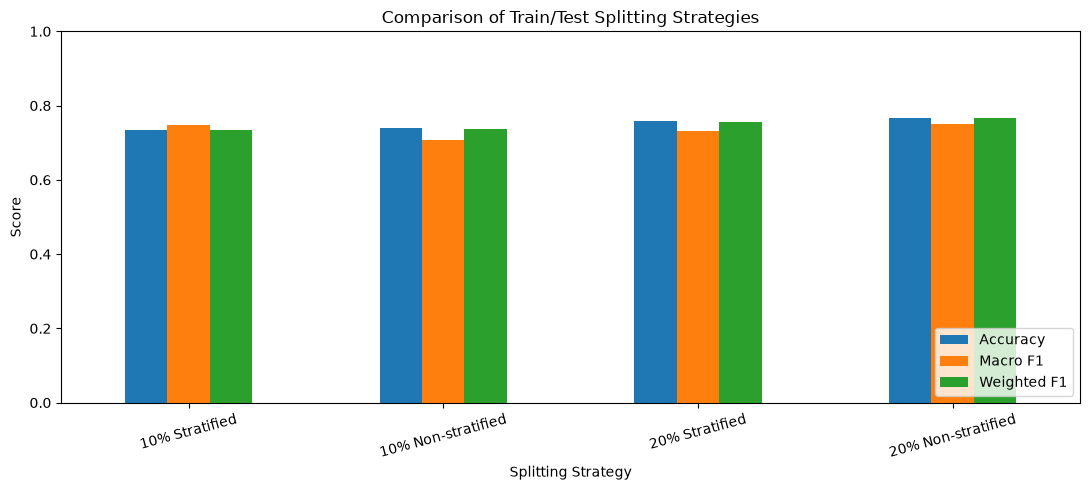

In [39]:

split_plot = split_comparison_df.set_index("Strategy")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

ax = split_plot.plot(
    kind="bar",
    figsize=(11, 5),
    rot=15
)

ax.set_title("Comparison of Train/Test Splitting Strategies")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


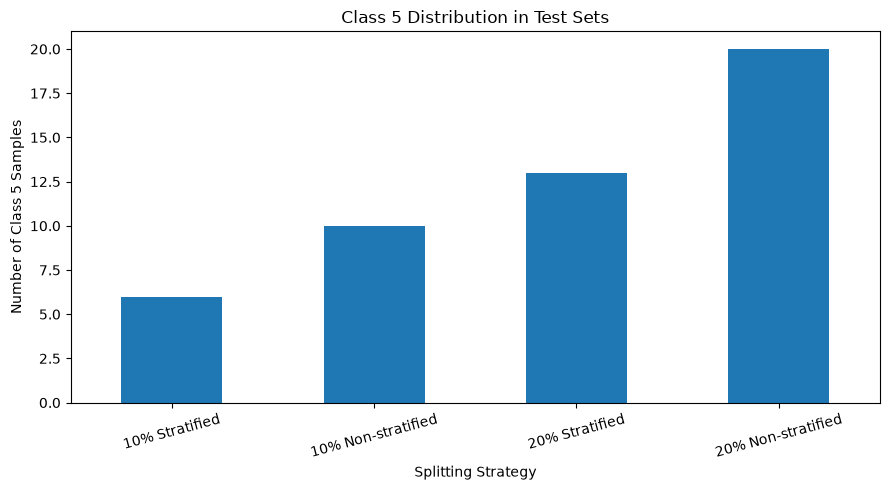

In [40]:


minority_class = class_distribution_df[
    class_distribution_df["Class"] == 5
].copy()

ax = minority_class.plot(
    x="Strategy",
    y="Test Count",
    kind="bar",
    figsize=(9, 5),
    rot=15,
    legend=False
)

ax.set_title("Class 5 Distribution in Test Sets")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Number of Class 5 Samples")

plt.tight_layout()
plt.show()




-- A.5. Distribuția clasei minoritare
Graficul prezintă numărul de exemple din clasa 5 în seturile de testare, pentru fiecare strategie de împărțire a datelor.
În cazul împărțirii stratificate, clasa 5 conține 6 exemple pentru testarea de 10% și 13 exemple pentru testarea de 20%. În variantele nestratificate, numărul acestora crește la 10, respectiv 20.
Diferențele arată că împărțirea nestratificată poate modifica reprezentarea clasei minoritare în setul de testare. Stratificarea păstrează proporția inițială a clasei 5, de aproximativ 2.18%, fiind astfel mai potrivită pentru o evaluare controlată a unui dataset dezechilibrat.

In [41]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src" / "common.py").exists():
    project_root = project_root.parent.parent

sys.path.insert(0, str(project_root / "src"))

from common import build_features
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier

from common import build_features

df_a6 = pd.read_csv(project_root / "df_fe.csv")

X_a6, y_a6, preprocessor_a6 = build_features(
    df_a6,
    encoding="onehot"
)

cv_strategies = {
    "5-Fold": StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "10-Fold": StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    ),
    "5-Fold Non-Stratified": KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "10-Fold Non-Stratified": KFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )
}

scoring_a6 = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        labels=np.arange(6),
        zero_division=0
    ),
    "weighted_f1": make_scorer(
        f1_score,
        average="weighted",
        labels=np.arange(6),
        zero_division=0
    )
}

print("Dataset:", X_a6.shape)
print("Numar clase:", y_a6.nunique())
print("Strategii CV:", list(cv_strategies.keys()))


Dataset: (2930, 92)
Numar clase: 6
Strategii CV: ['5-Fold', '10-Fold', '5-Fold Non-Stratified', '10-Fold Non-Stratified']


--A.6. Pregătirea strategiilor de Cross-Validation
Pentru a obține o evaluare mai stabilă a modelului XGBoost, sunt definite patru strategii de Cross-Validation: 5-Fold și 10-Fold, fiecare cu și fără stratificare.
Este utilizat dataset-ul cu feature engineering, format din 2930 de înregistrări și 92 de caracteristici, iar preprocesarea se bazează pe One-Hot Encoding.
În cazul Cross-Validation, datele sunt împărțite în 5 sau 10 subseturi (fold-uri). Modelul este antrenat și evaluat de mai multe ori, fiecare subset fiind folosit pe rând pentru validare.
StratifiedKFold păstrează aproximativ proporțiile celor șase clase în fiecare fold, în timp ce KFold nu impune această condiție.
Pentru compararea strategiilor sunt definite metricile Accuracy, Macro F1 și Weighted F1. Scopul experimentului este de a identifica o metodă de validare potrivită pentru dataset-ul dezechilibrat.

In [42]:

cv_results = []
cv_fold_results = []

for name, cv in cv_strategies.items():

    model_a6 = Pipeline([
        ("preprocessor", clone(preprocessor_a6)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=6,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model_a6,
        X_a6,
        y_a6,
        cv=cv,
        scoring=scoring_a6,
        n_jobs=1,
        return_train_score=True,
        error_score="raise"
    )

    cv_results.append({
        "CV Strategy": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Macro F1 Mean": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std(),
        "Weighted F1 Mean": scores["test_weighted_f1"].mean(),
        "Weighted F1 Std": scores["test_weighted_f1"].std(),
        "Train Macro F1": scores["train_macro_f1"].mean(),
        "Fit Time Mean (s)": scores["fit_time"].mean()
    })

    for fold_idx in range(cv.get_n_splits()):
        cv_fold_results.append({
            "CV Strategy": name,
            "Fold": fold_idx + 1,
            "Accuracy": scores["test_accuracy"][fold_idx],
            "Macro F1": scores["test_macro_f1"][fold_idx],
            "Weighted F1": scores["test_weighted_f1"][fold_idx],
            "Train Macro F1": scores["train_macro_f1"][fold_idx]
        })

cv_comparison_df = pd.DataFrame(cv_results)
cv_folds_df = pd.DataFrame(cv_fold_results)

display(cv_comparison_df.round(4))


,CV Strategy,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,Train Macro F1,Fit Time Mean (s)
0,5-Fold,0.7519,0.0144,0.7337,0.0133,0.7495,0.0144,0.9708,1.5439
1,10-Fold,0.7529,0.0207,0.7388,0.0277,0.7511,0.0207,0.9637,1.6824
2,5-Fold Non-Stratified,0.7563,0.0178,0.7436,0.0174,0.7545,0.0179,0.9688,1.4754
3,10-Fold Non-Stratified,0.7485,0.0268,0.7332,0.0400,0.7469,0.0271,0.9640,1.5340


--A.6. Compararea rezultatelor Cross-Validation
Pentru fiecare strategie de Cross-Validation, modelul XGBoost este evaluat folosind 5 sau 10 fold-uri, cu și fără stratificare. Sunt calculate mediile și deviațiile standard pentru Accuracy, Macro F1 și Weighted F1.
Strategia `5-Fold Non-Stratified` obține cel mai mare Macro F1 mediu (0.7436), însă `5-Fold Stratified` prezintă cea mai mică deviație standard pentru această metrică (0.0133), ceea ce indică rezultate mai uniforme între fold-uri.
Se observă și o diferență mare între Macro F1 pe antrenare (aproximativ 0.96–0.97) și pe validare (aproximativ 0.73–0.74), sugerând un posibil overfitting.
Pentru experimentele următoare este aleasă strategia `5-Fold Stratified`, deoarece păstrează proporțiile claselor, oferă rezultate relativ stabile și necesită mai puține antrenări decât varianta cu 10 fold-uri.

In [ ]:
print("Rezultatele fiecarui fold:")

display(
    cv_folds_df.round(4)
)

Rezultatele fiecarui fold:


,CV Strategy,Fold,Accuracy,Macro F1,Weighted F1,Train Macro F1
0,5-Fold,1,0.7577,0.7213,0.7558,0.9743
1,5-Fold,2,0.7679,0.7415,0.7664,0.9682
2,5-Fold,3,0.7423,0.7469,0.7408,0.9716
3,5-Fold,4,0.7628,0.7446,0.7585,0.9690
4,5-Fold,5,0.7287,0.7143,0.7261,0.9707
5,10-Fold,1,0.7713,0.7417,0.7685,0.9643
6,10-Fold,2,0.7543,0.7331,0.7517,0.9658
7,10-Fold,3,0.7782,0.7898,0.7776,0.9626
8,10-Fold,4,0.7474,0.6909,0.7457,0.9633
9,10-Fold,5,0.7509,0.7668,0.7517,0.9647


--A.6. Rezultatele individuale pentru fiecare fold
Tabelul prezintă valorile Accuracy, Macro F1 și Weighted F1 obținute pentru fiecare fold, atât pe validare, cât și Macro F1 pe antrenare.
Pentru strategia `5-Fold Stratified`, valorile Macro F1 variază între 0.7143 și 0.7469, indicând rezultate relativ apropiate între fold-uri. În schimb, `10-Fold Non-Stratified` prezintă variații mai mari, între 0.6615 și 0.7808.
În toate strategiile, Macro F1 pe antrenare rămâne peste 0.96, fiind considerabil mai mare decât pe validare. Această diferență sugerează existența unui posibil overfitting.
Rezultatele individuale susțin alegerea strategiei `5-Fold Stratified` pentru evaluările următoare, datorită variației mai reduse și păstrării proporțiilor claselor.

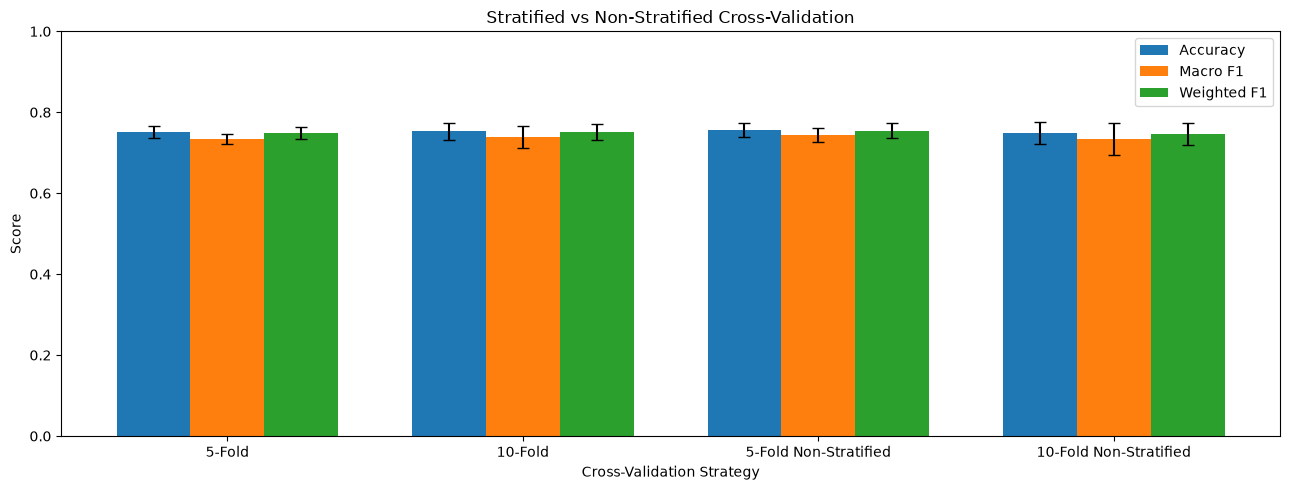

In [44]:

metrics_a6 = [
    ("Accuracy Mean", "Accuracy Std", "Accuracy"),
    ("Macro F1 Mean", "Macro F1 Std", "Macro F1"),
    ("Weighted F1 Mean", "Weighted F1 Std", "Weighted F1")
]

x = np.arange(len(cv_comparison_df))
width = 0.25

fig, ax = plt.subplots(figsize=(13, 5))

for i, (mean_col, std_col, label) in enumerate(metrics_a6):
    ax.bar(
        x + (i - 1) * width,
        cv_comparison_df[mean_col],
        width,
        yerr=cv_comparison_df[std_col],
        capsize=4,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(cv_comparison_df["CV Strategy"])
ax.set_ylim(0, 1)
ax.set_xlabel("Cross-Validation Strategy")
ax.set_ylabel("Score")
ax.set_title("Stratified vs Non-Stratified Cross-Validation")
ax.legend()

plt.tight_layout()
plt.show()

--A.6. Vizualizarea comparativă a strategiilor Cross-Validation
Graficul prezintă valorile medii pentru Accuracy, Macro F1 și Weighted F1, împreună cu deviațiile standard reprezentate prin barele de eroare.
Se observă că performanțele medii sunt relativ apropiate între cele patru strategii. Totuși, `5-Fold Stratified` prezintă cele mai mici variații pentru Macro F1 (0.0133), în timp ce `10-Fold Non-Stratified` are cea mai mare variație (0.0400).
Graficul susține alegerea strategiei `5-Fold Stratified` pentru experimentele următoare, deoarece oferă rezultate mai uniforme între fold-uri și păstrează proporțiile claselor.

In [46]:

outlier_pids_a6 = [
    908154235,
    908154195,
    908154205
]

outlier_mask_a6 = df_a6["PID"].isin(outlier_pids_a6).to_numpy()

assert len(set(outlier_pids_a6)) == 3
assert outlier_mask_a6.sum() == 3

cv_outliers = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Outlieri identificati:", outlier_mask_a6.sum())
print("Numar fold-uri:", cv_outliers.get_n_splits())


Outlieri identificati: 3
Numar fold-uri: 5


--A.6. Pregătirea comparării outlierilor prin Cross-Validation
Pentru a verifica mai bine influența outlierilor asupra performanței modelului, sunt selectate cele trei observații identificate anterior, folosind valorile PID.
Este definită strategia `StratifiedKFold` cu 5 fold-uri, aleasă în urma comparației anterioare. Aceasta permite evaluarea modelului pe mai multe împărțiri ale datelor, păstrând aproximativ proporțiile celor șase clase.
Rezultatele confirmă identificarea celor trei outlieri și pregătirea celor cinci fold-uri. În etapa următoare va fi comparată performanța modelului cu și fără aceste observații.

In [47]:

outlier_cv_results = []

for fold_idx, (train_idx, val_idx) in enumerate(
    cv_outliers.split(X_a6, y_a6),
    start=1
):

    X_train_full = X_a6.iloc[train_idx]
    y_train_full = y_a6.iloc[train_idx]

    X_val = X_a6.iloc[val_idx]
    y_val = y_a6.iloc[val_idx]

    train_outlier_mask = outlier_mask_a6[train_idx]

    training_variants = {
        "With Outliers": (
            X_train_full,
            y_train_full
        ),
        "Without Outliers": (
            X_train_full.iloc[~train_outlier_mask],
            y_train_full.iloc[~train_outlier_mask]
        )
    }

    for variant, (X_train_current, y_train_current) in training_variants.items():

        model_outlier_cv = Pipeline([
            ("preprocessor", clone(preprocessor_a6)),
            ("classifier", XGBClassifier(
                objective="multi:softprob",
                num_class=6,
                n_estimators=100,
                max_depth=4,
                learning_rate=0.1,
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            ))
        ])

        model_outlier_cv.fit(
            X_train_current,
            y_train_current
        )

        predictions = model_outlier_cv.predict(X_val)

        outlier_cv_results.append({
            "Fold": fold_idx,
            "Variant": variant,
            "Train Samples": len(X_train_current),
            "Outliers Removed": (
                int(train_outlier_mask.sum())
                if variant == "Without Outliers"
                else 0
            ),
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val,
                predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Weighted F1": f1_score(
                y_val,
                predictions,
                labels=np.arange(6),
                average="weighted",
                zero_division=0
            )
        })

outlier_cv_df = pd.DataFrame(outlier_cv_results)

display(outlier_cv_df.round(4))


,Fold,Variant,Train Samples,Outliers Removed,Accuracy,Macro F1,Weighted F1
0,1,With Outliers,2344,0,0.7577,0.7213,0.7558
1,1,Without Outliers,2341,3,0.7491,0.7184,0.7472
2,2,With Outliers,2344,0,0.7679,0.7415,0.7664
3,2,Without Outliers,2342,2,0.7713,0.7465,0.7698
4,3,With Outliers,2344,0,0.7423,0.7469,0.7408
5,3,Without Outliers,2341,3,0.7457,0.7562,0.7446
6,4,With Outliers,2344,0,0.7628,0.7446,0.7585
7,4,Without Outliers,2343,1,0.7713,0.7675,0.7670
8,5,With Outliers,2344,0,0.7287,0.7143,0.7261
9,5,Without Outliers,2341,3,0.7321,0.7127,0.7291


--A.6. Compararea performanței cu și fără outlieri pe fiecare fold
Pentru fiecare dintre cele cinci fold-uri sunt antrenate două variante ale modelului XGBoost: una care păstrează outlierii și una care îi elimină doar din setul de antrenare. Setul de validare rămâne identic pentru ambele variante.
Rezultatele arată că eliminarea outlierilor îmbunătățește Macro F1 în fold-urile 2, 3 și 4, dar îl reduce în fold-urile 1 și 5. Cea mai mare îmbunătățire apare în fold-ul 4, unde Macro F1 crește de la 0.7446 la 0.7675.
Numărul outlierilor eliminați diferă între fold-uri, deoarece unele observații se află în setul de validare și nu pot fi eliminate din antrenare.
Rezultatele indică faptul că eliminarea outlierilor nu produce îmbunătățiri constante, fiind necesară compararea valorilor medii pentru a evalua efectul general asupra modelului.

In [48]:

outlier_cv_summary = outlier_cv_df.groupby("Variant").agg(
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_Std=("Accuracy", "std"),
    Macro_F1_Mean=("Macro F1", "mean"),
    Macro_F1_Std=("Macro F1", "std"),
    Weighted_F1_Mean=("Weighted F1", "mean"),
    Weighted_F1_Std=("Weighted F1", "std")
)

display(outlier_cv_summary.round(4))

print("\nDiferenta medie Without - With:")

for metric in ["Accuracy", "Macro F1", "Weighted F1"]:
    means = outlier_cv_df.groupby("Variant")[metric].mean()

    difference = (
        means["Without Outliers"] -
        means["With Outliers"]
    )

    print(f"{metric}: {difference:+.4f}")


,Accuracy_Mean,Accuracy_Std,Macro_F1_Mean,Macro_F1_Std,Weighted_F1_Mean,Weighted_F1_Std
Variant,,,,,,
With Outliers,0.7519,0.0161,0.7337,0.0149,0.7495,0.0161
Without Outliers,0.7539,0.0171,0.7403,0.0238,0.7516,0.0169



Diferenta medie Without - With:
Accuracy: +0.0020
Macro F1: +0.0065
Weighted F1: +0.0020


--A.6. Rezultatele medii ale comparației cu și fără outlieri
Pentru a evalua efectul general al eliminării outlierilor, sunt calculate mediile și deviațiile standard ale metricilor obținute pe cele cinci fold-uri.
Rezultatele arată o îmbunătățire ușoară după eliminarea outlierilor: Accuracy crește de la 0.7519 la 0.7539, Macro F1 de la 0.7337 la 0.7403, iar Weighted F1 de la 0.7495 la 0.7516.
Totuși, deviația standard pentru Macro F1 crește de la 0.0149 la 0.0238, ceea ce indică rezultate mai variabile între fold-uri.
Deoarece îmbunătățirile sunt reduse și eliminarea outlierilor nu aduce rezultate mai stabile, păstrarea acestora rămâne o alegere justificată pentru experimentele următoare.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier

from common import build_features

df_a7 = pd.read_csv("df_fe.csv")

X_a7, y_a7, preprocessor_a7 = build_features(
    df_a7,
    encoding="onehot"
)

cv_a7 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_a7 = Pipeline([
    ("preprocessor", clone(preprocessor_a7)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("Dataset:", X_a7.shape)
print("Numar clase:", y_a7.nunique())
print("Cross-validation: 5-Fold Stratified")

Dataset: (2930, 92)
Numar clase: 6
Cross-validation: 5-Fold Stratified


--A.7. Pregătirea analizei Learning Curve
Pentru a analiza modul în care dimensiunea setului de antrenare influențează performanța modelului XGBoost, este pregătit experimentul Learning Curve.
Se utilizează dataset-ul cu feature engineering, care conține 2930 de înregistrări, 92 de caracteristici și șase clase de preț. Modelul folosește One-Hot Encoding și aceiași hiperparametri ca în experimentele anterioare.
Evaluarea se va realiza prin `StratifiedKFold` cu 5 fold-uri, pentru a păstra aproximativ proporțiile claselor.
Scopul experimentului este compararea performanței pe antrenare și validare, pentru a identifica eventuale probleme de overfitting sau underfitting.

In [51]:

from sklearn.metrics import make_scorer, f1_score

macro_f1_scorer_a7 = make_scorer(
    f1_score,
    average="macro",
    labels=np.arange(6),
    zero_division=0
)

train_sizes_a7 = np.linspace(0.2, 1.0, 9)

train_sizes_abs, train_scores, validation_scores = learning_curve(
    estimator=model_a7,
    X=X_a7,
    y=y_a7,
    train_sizes=train_sizes_a7,
    cv=cv_a7,
    scoring=macro_f1_scorer_a7,
    shuffle=True,
    random_state=42,
    n_jobs=1,
    error_score="raise"
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

learning_results_df = pd.DataFrame({
    "Training Samples": train_sizes_abs,
    "Train Macro F1 Mean": train_mean,
    "Train Macro F1 Std": train_std,
    "Validation Macro F1 Mean": validation_mean,
    "Validation Macro F1 Std": validation_std,
    "Generalization Gap": train_mean - validation_mean
})

display(learning_results_df.round(4))


,Training Samples,Train Macro F1 Mean,Train Macro F1 Std,Validation Macro F1 Mean,Validation Macro F1 Std,Generalization Gap
0,468,1.0000,0.0000,0.6809,0.0241,0.3191
1,703,1.0000,0.0000,0.6637,0.0548,0.3363
2,937,0.9964,0.0015,0.7004,0.0181,0.2960
3,1172,0.9937,0.0022,0.7152,0.0192,0.2785
4,1406,0.9889,0.0027,0.7103,0.0150,0.2786
5,1640,0.9837,0.0024,0.7221,0.0192,0.2615
6,1875,0.9804,0.0018,0.7300,0.0134,0.2505
7,2109,0.9746,0.0020,0.7269,0.0210,0.2477
8,2344,0.9702,0.0018,0.7301,0.0179,0.2400


--A.7. Analiza rezultatelor Learning Curve
Sunt evaluate performanțele modelului XGBoost pentru nouă dimensiuni ale setului de antrenare, utilizând validare încrucișată cu 5 fold-uri și metrica Macro F1.
Pe măsură ce numărul de exemple crește de la 468 la 2344, scorul Macro F1 pe validare crește în general de la 0.6809 la 0.7301, în timp ce scorul pe antrenare scade de la 1.0000 la 0.9702.
Diferența dintre cele două scoruri se reduce de la 0.3191 la 0.2400, dar rămâne ridicată, ceea ce indică overfitting. Creșterea cantității de date îmbunătățește generalizarea, însă nu elimină complet această problemă.

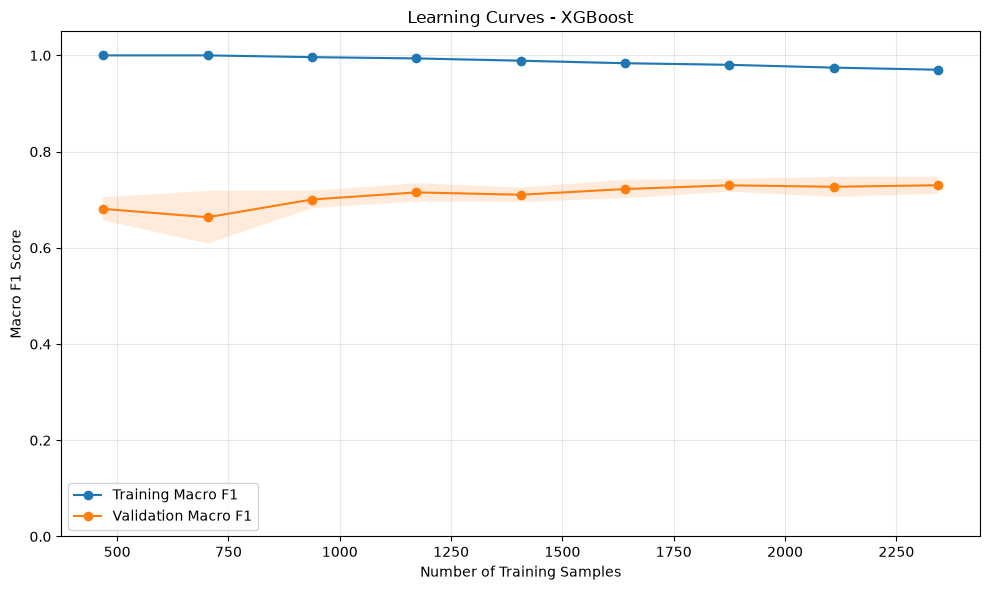

In [52]:

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Training Macro F1"
)

plt.plot(
    train_sizes_abs,
    validation_mean,
    marker="o",
    label="Validation Macro F1"
)

plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes_abs,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1 Score")
plt.title("Learning Curves - XGBoost")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


-A.7. Interpretarea graficului Learning Curves
Graficul prezintă evoluția scorului Macro F1 pe seturile de antrenare și validare, în funcție de numărul de exemple utilizate.
Scorul pe antrenare rămâne foarte ridicat, în timp ce scorul pe validare crește treptat și se stabilizează în jurul valorii de 0.73. Diferența dintre cele două curbe indică overfitting, deși aceasta se reduce odată cu creșterea setului de antrenare.
Rezultatele sugerează că modelul ar putea beneficia de ajustarea hiperparametrilor pentru îmbunătățirea generalizării.

In [53]:

final_train_f1 = train_mean[-1]
final_validation_f1 = validation_mean[-1]
final_gap = final_train_f1 - final_validation_f1

print(f"Train Macro F1: {final_train_f1:.4f}")
print(f"Validation Macro F1: {final_validation_f1:.4f}")
print(f"Generalization Gap: {final_gap:.4f}")

print("\nEvolutia scorului de validare:")
print(
    f"Primul punct: {validation_mean[0]:.4f}"
)
print(
    f"Ultimul punct: {validation_mean[-1]:.4f}"
)

if final_gap > 0.10:
    print(
        "\nDiferenta mare intre train si validare "
        "sugereaza overfitting."
    )
else:
    print(
        "\nDiferenta dintre train si validare "
        "este relativ redusa."
    )


Train Macro F1: 0.9702
Validation Macro F1: 0.7301
Generalization Gap: 0.2400

Evolutia scorului de validare:
Primul punct: 0.6809
Ultimul punct: 0.7301

Diferenta mare intre train si validare sugereaza overfitting.


-A.7. Concluzia analizei Learning Curves
La dimensiunea maximă a setului de antrenare, modelul obține un Macro F1 de 0.9702 pe train și 0.7301 pe validare, cu o diferență de 0.2400.
Scorul de validare crește de la 0.6809 la 0.7301, ceea ce arată că mai multe date contribuie la îmbunătățirea performanței. Totuși, diferența ridicată dintre train și validare indică overfitting și justifică optimizarea ulterioară a hiperparametrilor.

In [54]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier

from common import build_features

df_a8 = pd.read_csv("df_fe.csv")

X_a8, y_a8, preprocessor_a8 = build_features(
    df_a8,
    encoding="onehot"
)

class_counts_a8 = y_a8.value_counts().sort_index()

class_distribution_a8 = pd.DataFrame({
    "Class": class_counts_a8.index,
    "Samples": class_counts_a8.values,
    "Percentage": (
        class_counts_a8.values / len(y_a8) * 100
    )
})

display(class_distribution_a8.round(2))

print(
    "Imbalance ratio:",
    round(class_counts_a8.max() / class_counts_a8.min(), 2)
)


,Class,Samples,Percentage
0,0,237,8.09
1,1,509,17.37
2,2,1037,35.39
3,3,686,23.41
4,4,397,13.55
5,5,64,2.18


Imbalance ratio: 16.2


-A.8. Analiza dezechilibrului claselor
Distribuția celor 2930 de observații arată un dezechilibru între cele șase clase de preț. Clasa 2 este majoritară, cu 1037 de exemple (35.39%), în timp ce clasa 5 conține doar 64 de exemple (2.18%).
Raportul de dezechilibru este de 16.2, ceea ce indică o diferență semnificativă între clase. Acest dezechilibru poate afecta performanța modelului pentru clasele mai puțin reprezentate, motiv pentru care este necesară evaluarea unor metode de ponderare a observațiilor.

In [55]:

cv_a8 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

imbalance_results = []
class_results = []

for fold_idx, (train_idx, val_idx) in enumerate(
    cv_a8.split(X_a8, y_a8),
    start=1
):

    X_train = X_a8.iloc[train_idx]
    X_val = X_a8.iloc[val_idx]

    y_train = y_a8.iloc[train_idx]
    y_val = y_a8.iloc[val_idx]

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    for strategy in ["Baseline", "Balanced Weights"]:

        model_a8 = Pipeline([
            ("preprocessor", clone(preprocessor_a8)),
            ("classifier", XGBClassifier(
                objective="multi:softprob",
                num_class=6,
                n_estimators=100,
                max_depth=4,
                learning_rate=0.1,
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            ))
        ])

        if strategy == "Balanced Weights":
            model_a8.fit(
                X_train,
                y_train,
                classifier__sample_weight=sample_weights
            )
        else:
            model_a8.fit(X_train, y_train)

        predictions = model_a8.predict(X_val)

        imbalance_results.append({
            "Fold": fold_idx,
            "Strategy": strategy,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro Precision": precision_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Macro Recall": recall_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Macro F1": f1_score(
                y_val, predictions,
                labels=np.arange(6),
                average="macro",
                zero_division=0
            ),
            "Weighted F1": f1_score(
                y_val, predictions,
                labels=np.arange(6),
                average="weighted",
                zero_division=0
            )
        })

        class_precision = precision_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        class_recall = recall_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        class_f1 = f1_score(
            y_val, predictions,
            labels=np.arange(6),
            average=None,
            zero_division=0
        )

        for class_id in range(6):
            class_results.append({
                "Fold": fold_idx,
                "Strategy": strategy,
                "Class": class_id,
                "Precision": class_precision[class_id],
                "Recall": class_recall[class_id],
                "F1": class_f1[class_id]
            })

imbalance_results_df = pd.DataFrame(imbalance_results)
class_results_df = pd.DataFrame(class_results)

display(imbalance_results_df.round(4))


,Fold,Strategy,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,Baseline,0.7577,0.7460,0.7077,0.7213,0.7558
1,1,Balanced Weights,0.7304,0.7238,0.7319,0.7221,0.7321
2,2,Baseline,0.7679,0.7779,0.7213,0.7415,0.7664
3,2,Balanced Weights,0.7628,0.7470,0.7638,0.7545,0.7626
4,3,Baseline,0.7423,0.7604,0.7356,0.7469,0.7408
5,3,Balanced Weights,0.7287,0.7280,0.7510,0.7385,0.7292
6,4,Baseline,0.7628,0.7709,0.7285,0.7446,0.7585
7,4,Balanced Weights,0.7406,0.7261,0.7425,0.7327,0.7398
8,5,Baseline,0.7287,0.7340,0.6991,0.7143,0.7261
9,5,Balanced Weights,0.7116,0.7080,0.7257,0.7164,0.7121


-A.8. Compararea strategiilor de ponderare
Sunt comparate două strategii de antrenare: Baseline, fără ponderarea claselor, și Balanced Weights, care atribuie ponderi mai mari observațiilor din clasele minoritare.
Evaluarea este realizată prin Stratified 5-Fold Cross-Validation, utilizând aceleași împărțiri pentru ambele strategii. Rezultatele diferă între fold-uri, iar ponderarea îmbunătățește Macro F1 în trei dintre cele cinci fold-uri.
Totuși, Balanced Weights obține valori mai mici ale Accuracy și Weighted F1 în toate cele cinci fold-uri. Pentru stabilirea strategiei finale este necesară compararea mediilor și a performanțelor pe fiecare clasă.

In [56]:

imbalance_summary_df = (
    imbalance_results_df
    .groupby("Strategy")
    .agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Macro_Precision_Mean=("Macro Precision", "mean"),
        Macro_Recall_Mean=("Macro Recall", "mean"),
        Macro_F1_Mean=("Macro F1", "mean"),
        Macro_F1_Std=("Macro F1", "std"),
        Weighted_F1_Mean=("Weighted F1", "mean"),
        Weighted_F1_Std=("Weighted F1", "std")
    )
)

display(imbalance_summary_df.round(4))

print("\nDiferenta Balanced - Baseline:")

for metric in ["Accuracy", "Macro Recall", "Macro F1", "Weighted F1"]:
    means = imbalance_results_df.groupby("Strategy")[metric].mean()

    difference = (
        means["Balanced Weights"] - means["Baseline"]
    )

    print(f"{metric}: {difference:+.4f}")


,Accuracy_Mean,Accuracy_Std,Macro_Precision_Mean,Macro_Recall_Mean,Macro_F1_Mean,Macro_F1_Std,Weighted_F1_Mean,Weighted_F1_Std
Strategy,,,,,,,,
Balanced Weights,0.7348,0.0188,0.7266,0.7430,0.7328,0.0149,0.7352,0.0184
Baseline,0.7519,0.0161,0.7578,0.7184,0.7337,0.0149,0.7495,0.0161



Diferenta Balanced - Baseline:
Accuracy: -0.0171
Macro Recall: +0.0246
Macro F1: -0.0009
Weighted F1: -0.0144


-A.8. Analiza rezultatelor medii
Rezultatele validării încrucișate arată că strategia Baseline obține un Macro F1 de 0.7337, comparativ cu 0.7328 pentru Balanced Weights. Diferența este foarte mică (-0.0009), ceea ce indică faptul că ponderarea nu aduce o îmbunătățire a acestei metrici.
Balanced Weights crește Macro Recall de la 0.7184 la 0.7430, dar reduce Accuracy de la 0.7519 la 0.7348 și Weighted F1 de la 0.7495 la 0.7352.
Prin urmare, strategia Baseline este păstrată ca variantă de referință, deoarece ponderarea nu îmbunătățește Macro F1 și reduce performanța generală. Totuși, efectul asupra claselor minoritare trebuie analizat separat.

In [57]:

class_summary_df = (
    class_results_df
    .groupby(["Strategy", "Class"])
    .agg(
        Precision_Mean=("Precision", "mean"),
        Recall_Mean=("Recall", "mean"),
        F1_Mean=("F1", "mean")
    )
    .reset_index()
)

display(class_summary_df.round(4))

class_5_comparison = (
    class_summary_df[class_summary_df["Class"] == 5]
    .set_index("Strategy")
)

print("\nRezultatele pentru clasa 5:")
display(class_5_comparison.round(4))


,Strategy,Class,Precision_Mean,Recall_Mean,F1_Mean
0,Balanced Weights,0,0.7355,0.7131,0.7213
1,Balanced Weights,1,0.6197,0.6759,0.6455
2,Balanced Weights,2,0.7899,0.7252,0.7554
3,Balanced Weights,3,0.7312,0.7506,0.7401
4,Balanced Weights,4,0.7802,0.8136,0.7961
5,Balanced Weights,5,0.7029,0.7795,0.7386
6,Baseline,0,0.7677,0.6582,0.7040
7,Baseline,1,0.6765,0.6190,0.6446
8,Baseline,2,0.7620,0.8255,0.7917
9,Baseline,3,0.7563,0.7506,0.7528



Rezultatele pentru clasa 5:


,Class,Precision_Mean,Recall_Mean,F1_Mean
Strategy,,,,
Balanced Weights,5,0.7029,0.7795,0.7386
Baseline,5,0.7835,0.6538,0.7076


-A.8. Analiza performanței pe fiecare clasă
Rezultatele arată că ponderarea observațiilor influențează diferit performanța fiecărei clase. Pentru clasa minoritară 5, Balanced Weights crește Recall de la 0.6538 la 0.7795 și F1 de la 0.7076 la 0.7386, dar reduce Precision de la 0.7835 la 0.7029.
În schimb, pentru clasa majoritară 2, F1 scade de la 0.7917 la 0.7554. Astfel, ponderarea ajută la identificarea mai multor exemple din clasa minoritară, însă afectează performanța altor clase.
Deoarece Macro F1 global nu se îmbunătățește, Baseline rămâne strategia de referință, iar ponderarea poate fi reevaluată în etapa de optimizare.

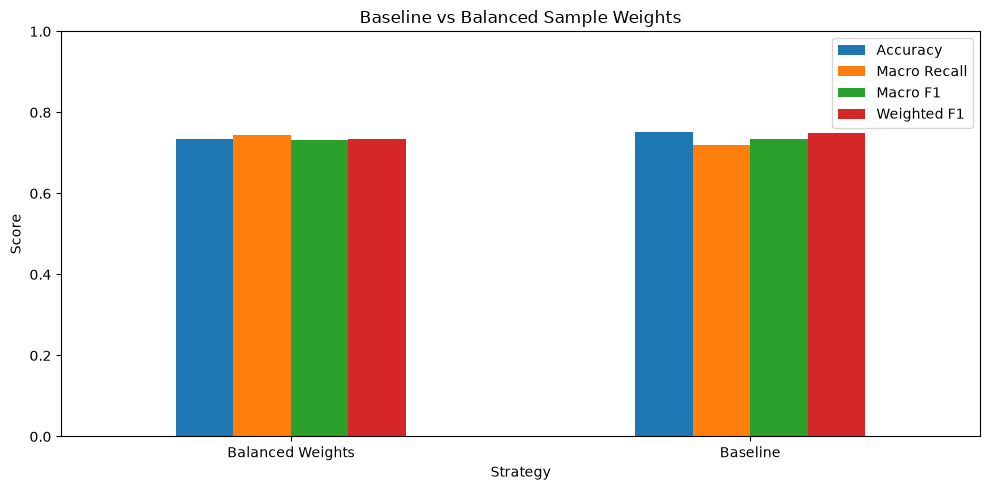

In [58]:

plot_metrics_a8 = [
    "Accuracy_Mean",
    "Macro_Recall_Mean",
    "Macro_F1_Mean",
    "Weighted_F1_Mean"
]

plot_labels_a8 = [
    "Accuracy",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

ax = imbalance_summary_df[plot_metrics_a8].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Baseline vs Balanced Sample Weights")
ax.set_xlabel("Strategy")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(plot_labels_a8)

plt.tight_layout()
plt.show()


-A.8. Compararea grafică a strategiilor de ponderare
Graficul compară performanțele medii ale celor două strategii, obținute prin validare încrucișată cu 5 fold-uri.
Balanced Weights obține un Macro Recall mai ridicat (0.7430 față de 0.7184), însă Baseline înregistrează rezultate mai bune pentru Accuracy și Weighted F1. Diferența dintre scorurile Macro F1 este foarte mică, de doar 0.0009 în favoarea Baseline.
Rezultatele confirmă că ponderarea claselor îmbunătățește identificarea unor observații, dar nu aduce un avantaj global pentru modelul evaluat.

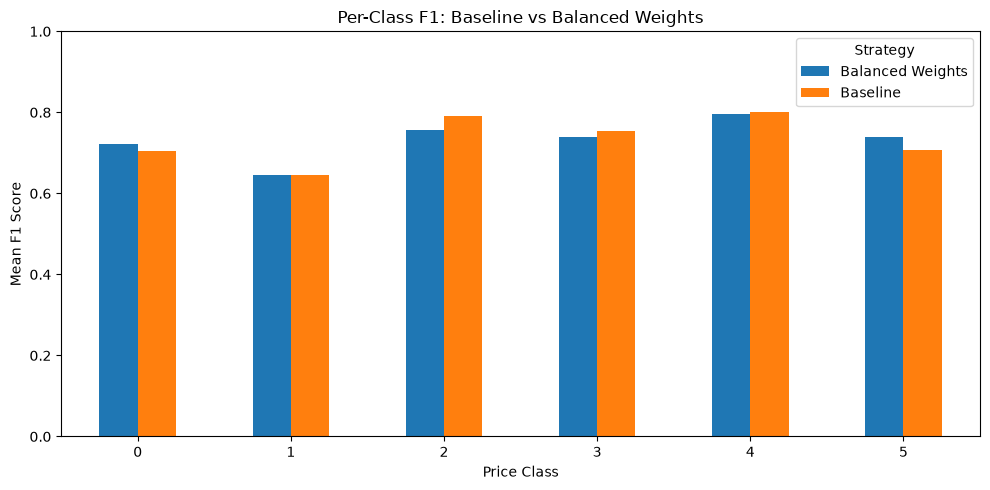

In [59]:

class_f1_plot = class_summary_df.pivot(
    index="Class",
    columns="Strategy",
    values="F1_Mean"
)

ax = class_f1_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Per-Class F1: Baseline vs Balanced Weights")
ax.set_xlabel("Price Class")
ax.set_ylabel("Mean F1 Score")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


-A.8. Compararea scorului F1 pentru fiecare clasă
Graficul prezintă diferențele dintre Baseline și Balanced Weights pentru fiecare dintre cele șase clase de preț.
Balanced Weights obține rezultate mai bune pentru clasele 0 și 5, în special pentru clasa minoritară 5, unde F1 crește de la 0.7076 la 0.7386. În schimb, Baseline are rezultate mai bune pentru clasele 2, 3 și 4, iar pentru clasa 1 diferența este foarte mică.
Rezultatele arată că ponderarea poate ajuta clasele mai puțin reprezentate, dar nu îmbunătățește uniform performanța modelului.

-Strategia finală recomandată
Pe baza experimentelor realizate în Partea A, a fost stabilită o configurație de bază pentru continuarea proiectului în părțile B și C.

Strategii alese și justificări

- Dataset: `df_fe.csv`, deoarece feature engineering a îmbunătățit Macro F1 de la 0.7155 la 0.7303.
- Encoding: One-Hot Encoding, pentru a păstra aceeași metodă de preprocesare în experimentele următoare. Native Encoding a obținut un rezultat mai bun (0.7446), dar comparația a fost realizată pe un singur split.
- Outlieri: se păstrează, deoarece eliminarea lor a adus o îmbunătățire relativ mică a Macro F1, de la 0.7337 la 0.7403, fără rezultate constant mai bune pe toate fold-urile.
- Train-test split: 80/20 stratificat, cu `random_state=42`, pentru a păstra aproximativ proporțiile celor șase clase de preț.
- Cross-validation: `StratifiedKFold` cu 5 fold-uri, deoarece a obținut un Macro F1 mediu de 0.7337 și cea mai mică deviație standard (0.0133) dintre strategiile comparate.
- Metrică principală: Macro F1, deoarece clasele sunt dezechilibrate și această metrică acordă aceeași importanță fiecărei clase.
- Sample weights: fără ponderi pentru baseline. Balanced Weights a redus ușor Macro F1 de la 0.7337 la 0.7328, deși a îmbunătățit Recall pentru clasa minoritară 5.
- SMOTE și Undersampling: nu au fost testate în această etapă.


Concluzii
Rezultatele Learning Curves au evidențiat o diferență de aproximativ 0.24 între Macro F1 pe antrenare și validare, ceea ce indică overfitting. Prin urmare, optimizarea hiperparametrilor trebuie să urmărească îmbunătățirea capacității de generalizare a modelului.

Pentru Partea B se recomandă testarea manuală a hiperparametrilor și analiza validation curves. În Partea C se va utiliza Optuna cu `TPESampler` pentru optimizarea automată, folosind Macro F1 ca obiectiv principal.

Ambele părți vor utiliza aceeași configurație de bază, pentru ca rezultatele să poată fi comparate. Optimizarea se va realiza doar pe setul de antrenare, folosind cross-validation, iar setul de test de 20% va fi păstrat pentru evaluarea finală.